<a href="https://colab.research.google.com/github/Elementos-Reconocimiento-Visual-UBA/PracticasERV_2026_4toBim/blob/main/Tarea_1_MIN_CUT_ST_y_NCUT/Tarea_1_MIN_CUT_S_T_Interactivo_y_NCut_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
*Nombre de Grupos*:

*Integrantes*:

# Segmentación por Grafos: MinCut Interactivo y Normalized Cuts (NCut) (PARTE 1 DE LA TAREA: IMAGENES FIJAS)

En el laboratorio ya vieron como funciona en práctica y en teoria el algoritmo de **s-t MinCut**.

Ahora vamos a dar el salto a problemas reales de visión computacional en imagenes.
Dividiremos esta esta etapa en dos grandes bloques:


1. **Segmentación Interactiva:** Vamos a escalar la implementación anterior con el fin de poder generalizar para diferentes imagenes. Usaremos la interacción del usuario (trazos sobre la imagen) para forzar las conexiones a la Fuente (Objeto) y al Sumidero (Fondo).

2. **Normalized Cuts (NCut):** Leeremos e implementaremos desde cero la formulación de Shi y Malik. Veremos por qué el MinCut tradicional falla en la segmentación no supervisada (tendiendo a cortar esquinas aisladas) y cómo al normalizar el costo del corte por el "volumen" de las particiones, logramos agrupamientos globales mucho más naturales.


# Librerias

In [ ]:
import numpy as np, cv2, time
import scipy.sparse as sp
import scipy.sparse.linalg as sla
import matplotlib.pyplot as plt
import networkx as nx
import json, base64, uuid, io, time
from PIL import Image
from IPython.display import HTML, display
from ipywidgets import interact, IntSlider
from skimage import util, data, transform, color
import pytest
from google.colab import files, output
import cv2
from skimage import data

# Parte A: corte mínimo s-t interactivo

En el Laboratorio 2 segmentaron una imagen con un corte mínimo s-t donde:


- Cada píxel es un vértice

- Los **n-links** unen vecinos con la penalidad de frontera $B(I_p, I_q)$,

- Los **t-links** atan las semillas a la fuente y al sumidero (donde las semillas eran rectángulos o poligonos escritos a mano en el código)

Ahora vamos a hacer lo mismo, pero de forma interactiva pintando las semillas con el mouse.

En esta sección vamos a reutilizar las funciones realizadas en el laboratorio 2 y crear solamente 2 funciones más

## Parte 1: Funciones del laboratorio anterior

## A.1 Las funciones del Laboratorio 2

Pegá acá tus funciones del Laboratorio 2 (las que completaron y pasaron los tests).
 Hay que tenerlas todas: `penalidad_frontera`, `agregar_n_links` ,`agregar_t_links`,`calcular_corte_minimo`, `construir_segmentacion` y las que ya venían dadas.

### Funciones dadas

In [ ]:
FUENTE = "s"
SUMIDERO = "t"

def id_de_pixel(fila, columna, ancho):
    """Convierte coordenadas 2D (fila, columna) a un ID de nodo 1D."""
    return fila * ancho + columna

def vecinos_derecha_y_abajo(fila, columna, alto, ancho):
    """Devuelve los vecinos a la derecha y abajo para no duplicar aristas."""
    vecinos = []
    if columna + 1 < ancho:
        vecinos.append((fila, columna + 1))
    if fila + 1 < alto:
        vecinos.append((fila + 1, columna))
    return vecinos

def calcular_capacidad_semilla(grafo):
  capacidad_maxima_por_pixel = max(grafo.out_degree(pixel, weight="capacity") for pixel in grafo.nodes)
  return 1 + capacidad_maxima_por_pixel

def penalidad_frontera(intensidad_p, intensidad_q, sigma=30):
    """
    Calcula la similitud. Funciona tanto para valores escalares (grises) como para arreglos de 3 valores (RGB) calculando la distancia euclídea.
    """
    diferencia = np.array(intensidad_p, dtype=float) - np.array(intensidad_q, dtype=float)
    distancia_cuadrada = np.sum(diferencia ** 2)
    return int(100 * np.exp(-distancia_cuadrada / (2 * (sigma ** 2))))

def calcular_capacidad_semilla(grafo):
    """Calcula una capacidad lo suficientemente grande ('infinita') para los T-links."""
    if len(grafo.edges) == 0:
        return 999999
    capacidad_maxima_por_pixel = max(grafo.out_degree(pixel, weight="capacity") for pixel in grafo.nodes)
    return 1 + capacidad_maxima_por_pixel

def construir_grafo(imagen, semillas_fondo, semillas_objeto, sigma=30):
    """Construye el grafo s-t completo con N-links y T-links."""
    alto, ancho = imagen.shape[:2]

    if semillas_fondo.shape != (alto, ancho) or semillas_objeto.shape != (alto, ancho):
        raise ValueError("Las semillas tienen que tener la misma forma (alto, ancho) que la imagen.")
    if not semillas_fondo.any() or not semillas_objeto.any():
        raise ValueError("Hace falta al menos una semilla de fondo y una de objeto.")

    grafo = nx.DiGraph()
    grafo.add_nodes_from(range(alto * ancho))

    #Agregamos los N-links
    for f in range(alto):
        for c in range(ancho):
            u = id_de_pixel(f, c, ancho)
            for f_v, c_v in vecinos_derecha_y_abajo(f, c, alto, ancho):
                v = id_de_pixel(f_v, c_v, ancho)
                cap = penalidad_frontera(imagen[f, c], imagen[f_v, c_v], sigma)

                #Tenemos que marcar aristas de ida y vuelta para que sea no dirigido
                grafo.add_edge(u, v, capacity=cap)
                grafo.add_edge(v, u, capacity=cap)

    #Agregamos los T-links y le ponemos la capacidad calculada
    cap_semilla = calcular_capacidad_semilla(grafo)

    for p in np.flatnonzero(semillas_fondo):
        grafo.add_edge(FUENTE, int(p), capacity=cap_semilla)

    for p in np.flatnonzero(semillas_objeto):
        grafo.add_edge(int(p), SUMIDERO, capacity=cap_semilla)

    return grafo


def dibujar_semillas(ax, imagen, semillas_fondo, semillas_objeto):
    """Visualiza la imagen con las semillas superpuestas."""
    if imagen.ndim == 2:
        imagen_rgb = np.dstack([imagen] * 3)
    else:
        imagen_rgb = imagen.copy()

    imagen_rgb[semillas_fondo] = (0, 0, 255) #Azul = Fondo
    imagen_rgb[semillas_objeto] = (255, 0, 0) #Rojo = Objeto

    ax.imshow(imagen_rgb)
    ax.set_title("Imagen y semillas\n(azul: fondo, rojo: objeto)")
    ax.axis("off")

### Funciones a dar

In [ ]:
def calcular_corte_minimo(grafo):
    """
    Calcula el corte mínimo del grafo.
    Debe devolver (valor_corte, conjunto_fuente, conjunto_sumidero)
    """
    pass

def construir_segmentacion(conjunto_sumidero, forma):
    """
    Toma los nodos del sumidero (objeto) y devuelve una máscara booleana 2D.
    """
    pass


def segmentar_con_grafos(imagen, semillas_fondo, semillas_objeto, sigma=30):
    """
    Pipeline completo: Construye el grafo -> Calcula MinCut -> Construye máscara 2D
    """
    #Dejen el return
    return construir_segmentacion(conjunto_sumidero, imagen.shape[:2])

In [ ]:
# ==========================================
# CÓDIGO DEL ALUMNO (COPIAR Y PEGAR DE LA PARTE 1)
# ==========================================

def calcular_corte_minimo(grafo):
    """
    Calcula el corte mínimo del grafo.
    Debe devolver (valor_corte, conjunto_fuente, conjunto_sumidero)
    """
    # TIP: recuerda usar nx.minimum_cut(grafo, FUENTE, SUMIDERO)
    valor_corte, (conjunto_fuente, conjunto_sumidero) = nx.minimum_cut(grafo, FUENTE, SUMIDERO)
    return valor_corte, conjunto_fuente, conjunto_sumidero


def construir_segmentacion(conjunto_sumidero, forma):
    """
    Toma los nodos del sumidero (objeto) y devuelve una máscara booleana 2D.
    """
    alto, ancho = forma
    segmentacion = np.zeros(alto * ancho, dtype=bool)

    # Descartamos el nodo terminal SUMIDERO
    ids_pixeles_objeto = [vertice for vertice in conjunto_sumidero if vertice != SUMIDERO]
    segmentacion[ids_pixeles_objeto] = True

    # Remodelamos la máscara 1D a 2D
    return segmentacion.reshape(forma)


def segmentar_con_grafos(imagen, semillas_fondo, semillas_objeto, sigma=30):
    """
    Pipeline completo: Construye el grafo -> Calcula MinCut -> Construye máscara 2D
    """
    grafo = construir_grafo(imagen, semillas_fondo, semillas_objeto, sigma)
    valor_corte, conjunto_fuente, conjunto_sumidero = calcular_corte_minimo(grafo)

    print(f"Capacidad del corte mínimo: {valor_corte}")

    return construir_segmentacion(conjunto_sumidero, imagen.shape[:2])

## A.2 Ejercicio: De los trazos a las semillas

El pincel de la interfaz devuelve los trazos realizados como una lista de puntos. Cada punto es una lista o tupla [x, y, radio, etiqueta]:

- x: Columna del punto en la imagen (píxeles, puede tener decimales)

- y: Fila del punto en la imagen (píxeles, puede tener decimales)

- radio: Radio del pincel en píxeles

- etiqueta: Tipo de trazo (1 para objeto, 2 para fondo)





### ¿Cómo se convierte cada punto en una máscara?

Cada punto pinta un disco sobre la imagen:

$$\text{disco} = \left\{(f, c) : (c - \text{round}(x))^2 + (f - \text{round}(y))^2 \le \text{radio}^2\right\}$$

donde $f$ representa la fila y $c$ la columna. Un punto con radio = 0 pinta únicamente el píxel $(\text{round}(y), \text{round}(x))$.

Ejemplo 1:

Para un único punto ubicado en $(x, y) = (7, 6)$ con un radio $r = 2.5$, se evalúa la distancia cuadrática desde el centro redondeado hacia los píxeles vecinos

Ejemplo 2:

Varios puntos ubicados en diferentes posicion con $r = 2$

### Regla de superposición
Los puntos se procesan en el orden estricto de la lista. Si un píxel es cubierto por más de un disco, prevalece el último trazo aplicado. Esto permite corregir errores (un trazo nuevo de fondo tapa a uno viejo de objeto y viceversa).

### Ejercicio
Programa la función trazos_a_semillas(trazos, forma).

- Entrada:

  - trazos: Lista con los trazos realizados [[x, y, radio, etiqueta], ...].
  - forma: Tupla (filas, columnas) con las dimensiones de la imagen.

- Salida:

  - Retorná una tupla de dos máscaras booleanas (semillas_fondo, semillas_objeto), ambas de dimensión forma.

In [ ]:
import numpy as np

def trazos_a_semillas(trazos, forma):
    """
    Convierte una lista de trazos del pincel en dos máscaras booleanas de semillas.

    Parámetros:
    trazos : Lista de elementos [x, y, radio, etiqueta].
        x = columna, y = fila, etiqueta: 1 (objeto), 2 (fondo).
    forma : Dimensiones de la imagen (filas, columnas).

    Retorna:
    semillas_fondo : ndarray (bool)
        Máscara booleana donde True indica píxeles marcados como fondo.
    semillas_objeto : ndarray (bool)
        Máscara booleana donde True indica píxeles marcados como objeto.
    """
    #Creamos una matriz de ceros para almacenar las etiquetas finales (0 = sin pintar)
    etiquetas = np.zeros(forma, dtype=np.uint8)

    #Generamos las grillas de índices de filas y columnas
    filas, columnas = np.indices(forma)

    #Recorremos los trazos en orden y pintar sobre la matriz 'etiquetas'
    for x, y, radio, etiqueta in trazos:
        #COMPLETAR
        pass

    #Devolvemos mascaras (semillas_fondo, semillas_objeto)
    semillas_fondo = (etiquetas == 2)
    semillas_objeto = (etiquetas == 1)

    return semillas_fondo, semillas_objeto

In [ ]:
import numpy as np

def trazos_a_semillas(trazos, forma):
    """
    Convierte una lista de trazos del pincel en dos máscaras booleanas de semillas.

    Parámetros:
    -----------
    trazos : list
        Lista de elementos [x, y, radio, etiqueta].
        x = columna, y = fila, etiqueta: 1 (objeto), 2 (fondo).
    forma : tuple
        Dimensiones de la imagen (filas, columnas).

    Retorna:
    --------
    semillas_fondo : ndarray (bool)
        Máscara booleana donde True indica píxeles marcados como fondo.
    semillas_objeto : ndarray (bool)
        Máscara booleana donde True indica píxeles marcados como objeto.
    """
    etiquetas = np.zeros(forma, dtype=np.uint8)

    filas, columnas = np.indices(forma)

    for x, y, radio, etiqueta in trazos:
        x_c, y_c = round(x), round(y)

        disco = (columnas - x_c)**2 + (filas - y_c)**2 <= radio**2

        etiquetas[disco] = etiqueta

    semillas_fondo = (etiquetas == 2)
    semillas_objeto = (etiquetas == 1)

    return semillas_fondo, semillas_objeto

### Imagen de Prueba

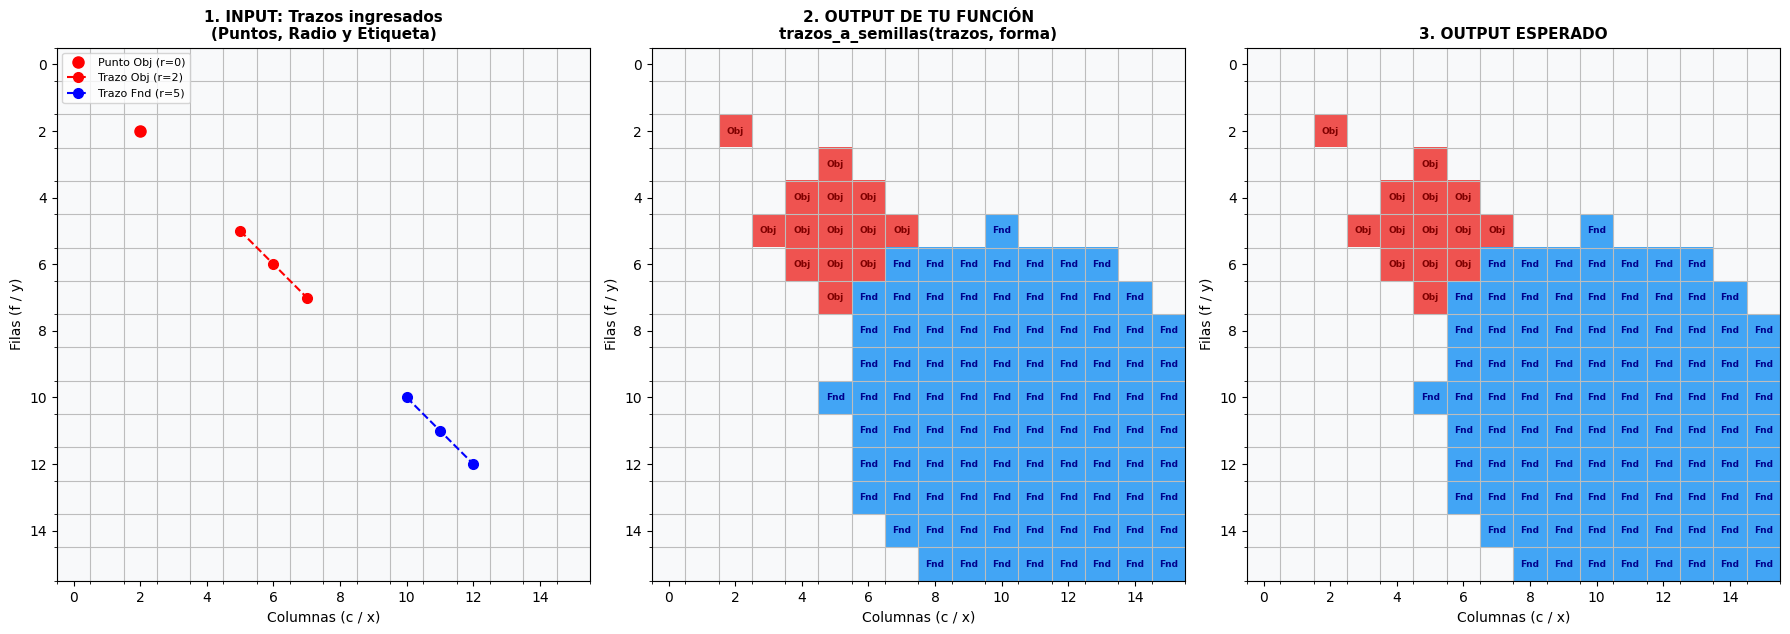

Tu función calculó exactamente la máscara esperada.


In [ ]:
forma_imagen = (16, 16)

trazo_1 = [[2, 2, 0, 1]]
trazo_2 = [
    [5, 5, 2, 1],
    [6, 6, 2, 1],
    [7, 7, 2, 1]
]
trazo_3 = [
    [10, 10, 5, 2],
    [11, 11, 5, 2],
    [12, 12, 5, 2]
]

trazos_input = trazo_1 + trazo_2 + trazo_3

#Obetnemos el output de la funcion realizada
semillas_fondo_out, semillas_objeto_out = trazos_a_semillas(trazos_input, forma_imagen)

#Output esperado
matriz_esperado = np.array([
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 2, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 0, 0],
    [0, 0, 0, 0, 0, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0],
    [0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2],
    [0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2],
    [0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2],
    [0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2],
    [0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2],
    [0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2],
    [0, 0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2],
    [0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2],
], dtype=np.uint8)

#Creamos el grafico
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
cmap = plt.cm.colors.ListedColormap(['#f8f9fa', '#ef5350', '#42a5f5'])

#GRAFICO: INPUT
ax1 = axes[0]
ax1.imshow(np.zeros(forma_imagen), cmap=plt.cm.colors.ListedColormap(['#f8f9fa']), origin='upper')

ax1.plot([p[0] for p in trazo_1], [p[1] for p in trazo_1], 'ro', markersize=8, label='Punto Obj (r=0)')
ax1.plot([p[0] for p in trazo_2], [p[1] for p in trazo_2], 'r--o', markersize=7, label='Trazo Obj (r=2)')
ax1.plot([p[0] for p in trazo_3], [p[1] for p in trazo_3], 'b--o', markersize=7, label='Trazo Fnd (r=5)')

ax1.set_title("1. INPUT: Trazos ingresados\n(Puntos, Radio y Etiqueta)", fontsize=11, fontweight='bold')
ax1.legend(loc='upper left', fontsize=8)

#GRAFICO: OUTPUT DE TU FUNCION
ax2 = axes[1]
matriz_out = np.zeros(forma_imagen, dtype=np.uint8)
matriz_out[semillas_objeto_out] = 1
matriz_out[semillas_fondo_out] = 2

ax2.imshow(matriz_out, cmap=cmap, origin='upper', vmin=0, vmax=2)
ax2.set_title("2. OUTPUT DE TU FUNCIÓN\ntrazos_a_semillas(trazos, forma)", fontsize=11, fontweight='bold')

for f in range(forma_imagen[0]):
    for c in range(forma_imagen[1]):
        if semillas_objeto_out[f, c]:
            ax2.text(c, f, 'Obj', ha='center', va='center', fontsize=6.5, color='maroon', weight='bold')
        elif semillas_fondo_out[f, c]:
            ax2.text(c, f, 'Fnd', ha='center', va='center', fontsize=6.5, color='darkblue', weight='bold')

#OUTPUT QUE SE ESPERA
ax3 = axes[2]
ax3.imshow(matriz_esperado, cmap=cmap, origin='upper', vmin=0, vmax=2)
ax3.set_title("3. OUTPUT ESPERADO", fontsize=11, fontweight='bold')

for f in range(forma_imagen[0]):
    for c in range(forma_imagen[1]):
        if matriz_esperado[f, c] == 1:
            ax3.text(c, f, 'Obj', ha='center', va='center', fontsize=6.5, color='maroon', weight='bold')
        elif matriz_esperado[f, c] == 2:
            ax3.text(c, f, 'Fnd', ha='center', va='center', fontsize=6.5, color='darkblue', weight='bold')

for ax in axes:
    ax.set_xticks(np.arange(-0.5, forma_imagen[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, forma_imagen[0], 1), minor=True)
    ax.grid(which='minor', color='#bdbdbd', linestyle='-', linewidth=0.8)
    ax.set_xlabel('Columnas (c / x)')
    ax.set_ylabel('Filas (f / y)')

plt.tight_layout()
plt.show()

#validamos
coincide_fondo = np.array_equal(semillas_fondo_out, matriz_esperado == 2)
coincide_objeto = np.array_equal(semillas_objeto_out, matriz_esperado == 1)

if coincide_fondo and coincide_objeto:
    print("Tu función calculó exactamente la máscara esperada.")
else:
    print("Hay diferencias entre tu output (Gráfico 2) y el esperado (Gráfico 3). Revisa tu lógica.")

### Tests

In [ ]:
def test_punto_unico_radio_cero():
    fondo, objeto = trazos_a_semillas([[3, 1, 0, 1]], (5, 6))
    assert fondo.shape == (5, 6) and objeto.shape == (5, 6), 'Las máscaras tienen que tener la forma pedida'
    assert fondo.dtype == bool and objeto.dtype == bool, 'Las máscaras tienen que ser booleanas'
    assert objeto.sum() == 1 and objeto[1, 3], 'Un punto [x=3, y=1, radio=0] pinta solo el píxel (fila 1, columna 3)'
    assert not fondo.any(), 'No se pintó fondo'

def test_redondeo_coordenadas():
    _, objeto = trazos_a_semillas([[2.6, 1.4, 0, 1]], (5, 6))
    assert objeto[1, 3] and objeto.sum() == 1, 'x = 2.6 e y = 1.4 se redondean a la columna 3 y la fila 1'

def test_area_disco():
    _, objeto = trazos_a_semillas([[5, 5, 2, 1]], (11, 11))
    assert objeto.sum() == 13, f'Un disco de radio 2 tiene 13 píxeles, no {objeto.sum()}'

def test_recorte_en_bordes():
    fondo, _ = trazos_a_semillas([[0, 0, 2, 2]], (5, 5))
    assert fondo.sum() == 6, 'Un disco de radio 2 centrado en la esquina deja 6 píxeles dentro de la imagen'

def test_superposicion_y_orden():
    fondo, objeto = trazos_a_semillas([[2, 2, 1, 1], [2, 2, 0, 2]], (5, 5))
    assert fondo[2, 2] and not objeto[2, 2], 'El punto de fondo (último) tiene que pisar al de objeto'
    assert objeto.sum() == 4, 'Del disco de objeto deberían quedar los otros 4 píxeles'
    assert not (fondo & objeto).any(), 'Las máscaras no se pueden superponer en ningún píxel'

def test_trazos_vacios():
    fondo, objeto = trazos_a_semillas([], (3, 4))
    assert not fondo.any() and not objeto.any(), 'Las máscaras deberían estar completamente en False'


pruebas = [
    ("1. Punto único", test_punto_unico_radio_cero),
    ("2. Redondeo", test_redondeo_coordenadas),
    ("3. Área del disco", test_area_disco),
    ("4. Recorte en bordes", test_recorte_en_bordes),
    ("5. Superposición y orden", test_superposicion_y_orden),
    ("6. Sin trazos", test_trazos_vacios),
]

print("Iniciando validación de trazos_a_semillas...\n" + "="*50)
tests_pasados = 0

for nombre, prueba in pruebas:
    try:
        prueba()
        print(f"{nombre}: Test pasado")
        tests_pasados += 1
    except AssertionError as e:
        print(f"{nombre}: FALLÓ\n   Detalle: {e}")
    except Exception as e:
        print(f"{nombre}: ERROR INESPERADO\n   {type(e).__name__}: {e}")

print("=" * 50)
if tests_pasados == len(pruebas):
    print("Tu función pasó todas las pruebas correctamente.")
else:
    print(f"Pasaste {tests_pasados} de {len(pruebas)} pruebas. Revisa los errores marcados.")

Iniciando validación de trazos_a_semillas...
1. Punto único: Test pasado
2. Redondeo: Test pasado
3. Área del disco: Test pasado
4. Recorte en bordes: Test pasado
5. Superposición y orden: Test pasado
6. Sin trazos: Test pasado
Tu función pasó todas las pruebas correctamente.


## A.3 Ejercicio: El valor del corte es el costo del borde

El algoritmo de Graph Cuts (corte mínimo) devuelve un valor numérico equivalente a la capacidad total del corte. ¿De dónde surge exactamente este valor?


El corte separa los vértices del grafo en dos conjuntos: el lado de la fuente $s$ (Fondo) y el lado del sumidero $t$ (Objeto).

La capacidad total es la suma de los pesos de las aristas que se deben romper para separar ambos lados:

- Los **t-links** nunca se cortan: Dado que la constante $K$ asignada a los píxeles semilla es mayor que la suma de todas las aristas posibles de un píxel, resulta imposible (mucho más costoso) cortar una semilla que romper sus conexiones entre vecinos (n-links). (Tambien pueden pensar que los pixeles semillas estan unidos con PESO INFINITO A SU LADO DE LA FUENTE/SUMIDERO)

- Las aristas entre vecinos (**n-links**): Cada par de vecinos contiguos que quedan asignados a etiquetas distintas (uno en objeto y el otro en fondo) interrumpe su conexión. Para no duplicar aristas, recorremos la grilla evaluando únicamente las relaciones derecha y abajo.

Por lo tanto, la capacidad del corte mínimo coincide exactamente con la suma de las penalidades de frontera $B(I_p, I_q)$ sobre todos los pares de vecinos con etiquetas opuestas, lo que representa el costo total del borde de la segmentación.

Implementá la función costo_del_borde(imagen, segmentacion, sigma)

- Entrada:
  - imagen: Matriz $H \times W$ con las intensidades de la imagen original.
  - segmentacion: Máscara booleana $H \times W$ donde True representa Objeto y False representa Fondo.
  - sigma: Parámetro de sensibilidad para el cálculo de penalidad_frontera(I_p, I_q, sigma).

- Salida:
  - Retorná una tupla (costo, borde):
    - costo: Suma acumulada (flotante) de la penalidad de frontera de todas las transiciones Objeto/Fondo.
    - borde: Máscara booleana $H \times W$ con valor True únicamente en los píxeles de Objeto que limitan con al menos un vecino de Fondo (O sea, de esta forma vamos a poder crear una mascara intermedia entre objeto y fondo para que podamos segmentar. Es decir, son los puntos frontera)

In [ ]:
def costo_del_borde(imagen, segmentacion, sigma=30):
    """
    Calcula la suma de penalidades de frontera entre píxeles vecinos con etiquetas distintas y construye la máscara booleana del borde del objeto.

    Parámetros:
    imagen : ndarray (2D)
        Matriz de intensidad de la imagen original.
    segmentacion : ndarray (bool, 2D)
        Máscara donde True representa Objeto y False representa Fondo.
    sigma : float
        Parámetro de suavizado para penalidad_frontera.

    Retorna:
    costo : float
        Costo acumulado de las aristas cortadas en la frontera.
    borde : ndarray (bool, 2D)
        Máscara con True en píxeles de Objeto colindantes con el Fondo.
    """
    alto, ancho = imagen.shape
    costo = 0.0
    borde = np.zeros((alto, ancho), dtype=bool)

    for fila in range(alto):
        for columna in range(ancho):
            for fila_vecino, columna_vecino in vecinos_derecha_y_abajo(fila, columna, alto, ancho):
                #Completar
                # 1.Verifica si el píxel actual y su vecino pertenecen a etiquetas distintas
                # 2.Acumula la penalidad_frontera(imagen[p], imagen[q], sigma) en 'costo'
                # 3.Marca con True en 'borde' al píxel que pertenezca al OBJETO
                pass

    return costo, borde

In [ ]:
import numpy as np

def costo_del_borde(imagen, segmentacion, sigma=30):
    """
    Calcula la suma de penalidades de frontera entre píxeles vecinos con etiquetas distintas
    y construye la máscara booleana del borde del objeto.
    """
    alto, ancho = imagen.shape[:2]  # Tomar solo (alto, ancho) ignorando canales RGB
    costo = 0.0
    borde = np.zeros((alto, ancho), dtype=bool)

    for fila in range(alto):
        for columna in range(ancho):
            for fila_vecino, columna_vecino in vecinos_derecha_y_abajo(fila, columna, alto, ancho):
                if segmentacion[fila, columna] != segmentacion[fila_vecino, columna_vecino]:
                    p1 = imagen[fila, columna]
                    p2 = imagen[fila_vecino, columna_vecino]
                    costo += penalidad_frontera(p1, p2, sigma)

                    if segmentacion[fila, columna]:
                        borde[fila, columna] = True
                    else:
                        borde[fila_vecino, columna_vecino] = True

    return costo, borde

#### IMAGEN DE PRUEBA

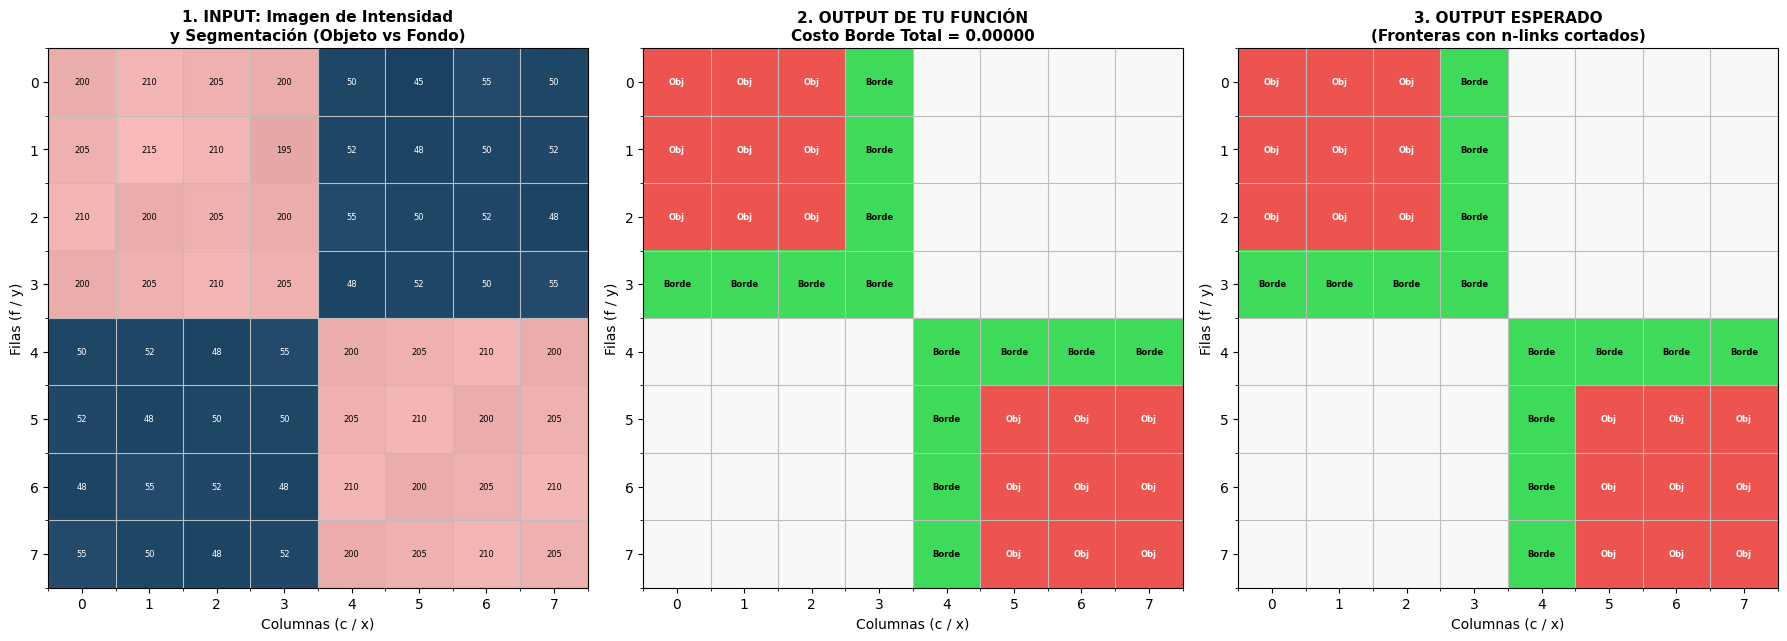

In [ ]:
#Input
imagen = np.array([
    [200, 210, 205, 200,  50,  45,  55,  50],
    [205, 215, 210, 195,  52,  48,  50,  52],
    [210, 200, 205, 200,  55,  50,  52,  48],
    [200, 205, 210, 205,  48,  52,  50,  55],
    [ 50,  52,  48,  55, 200, 205, 210, 200],
    [ 52,  48,  50,  50, 205, 210, 200, 205],
    [ 48,  55,  52,  48, 210, 200, 205, 210],
    [ 55,  50,  48,  52, 200, 205, 210, 205]
], dtype=np.uint8)

segmentacion = np.array([
    [1, 1, 1, 1, 0, 0, 0, 0],
    [1, 1, 1, 1, 0, 0, 0, 0],
    [1, 1, 1, 1, 0, 0, 0, 0],
    [1, 1, 1, 1, 0, 0, 0, 0],
    [0, 0, 0, 0, 1, 1, 1, 1],
    [0, 0, 0, 0, 1, 1, 1, 1],
    [0, 0, 0, 0, 1, 1, 1, 1],
    [0, 0, 0, 0, 1, 1, 1, 1]
], dtype=bool)

#Ejecutamos la funcion
costo_calculado, borde_calculado = costo_del_borde(imagen, segmentacion, sigma=30)

#GRAFICOS
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

#INPUT
ax1 = axes[0]
ax1.imshow(imagen, cmap='gray', origin='upper')
mask_overlay = np.zeros((*segmentacion.shape, 4))
mask_overlay[segmentacion] = [0.93, 0.33, 0.31, 0.4]  # Objeto (Rojo)
mask_overlay[~segmentacion] = [0.26, 0.65, 0.96, 0.4] # Fondo (Azul)
ax1.imshow(mask_overlay, origin='upper')
ax1.set_title("1. INPUT: Imagen de Intensidad\ny Segmentación (Objeto vs Fondo)", fontsize=11, fontweight='bold')

for f in range(imagen.shape[0]):
    for c in range(imagen.shape[1]):
        ax1.text(c, f, str(imagen[f, c]), ha='center', va='center', fontsize=6,
                 color='white' if imagen[f, c] < 100 else 'black')

#Output de la Función
ax2 = axes[1]
matriz_out = np.zeros((*segmentacion.shape, 3))
matriz_out[~segmentacion] = [0.97, 0.98, 0.98]
matriz_out[segmentacion] = [0.93, 0.33, 0.31]
matriz_out[borde_calculado] = [0.24, 0.86, 0.35] # Borde (Verde)

ax2.imshow(matriz_out, origin='upper')
ax2.set_title(f"2. OUTPUT DE TU FUNCIÓN\nCosto Borde Total = {costo_calculado:.5f}", fontsize=11, fontweight='bold')

for f in range(segmentacion.shape[0]):
    for c in range(segmentacion.shape[1]):
        if borde_calculado[f, c]:
            ax2.text(c, f, 'Borde', ha='center', va='center', fontsize=6, color='black', weight='bold')
        elif segmentacion[f, c]:
            ax2.text(c, f, 'Obj', ha='center', va='center', fontsize=6, color='white', weight='bold')

#Output Esperado
ax3 = axes[2]
ax3.imshow(matriz_out, origin='upper')
ax3.set_title("3. OUTPUT ESPERADO\n(Fronteras con n-links cortados)", fontsize=11, fontweight='bold')

for f in range(segmentacion.shape[0]):
    for c in range(segmentacion.shape[1]):
        if borde_calculado[f, c]:
            ax3.text(c, f, 'Borde', ha='center', va='center', fontsize=6, color='black', weight='bold')
        elif segmentacion[f, c]:
            ax3.text(c, f, 'Obj', ha='center', va='center', fontsize=6, color='white', weight='bold')

for ax in axes:
    ax.set_xticks(np.arange(-0.5, imagen.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, imagen.shape[0], 1), minor=True)
    ax.grid(which='minor', color='#bdbdbd', linestyle='-', linewidth=0.8)
    ax.set_xlabel('Columnas (c / x)')
    ax.set_ylabel('Filas (f / y)')

plt.tight_layout()
plt.show()

#### Tests

In [ ]:
def test_un_solo_borde_1d():
    img = np.array([[0, 0, 100, 100]], dtype=np.uint8)
    seg = np.array([[False, False, True, True]])
    costo, borde = costo_del_borde(img, seg, 30)

    costo_esperado = penalidad_frontera(0, 100, 30)
    assert costo == costo_esperado, f'Solo cuenta el par que cruza el borde. Esperado {costo_esperado}, obtenido {costo}'
    assert borde.tolist() == [[False, False, True, False]], 'El borde es el píxel de objeto que toca al fondo'

def test_sin_borde():
    img = np.array([[0, 0, 100, 100]], dtype=np.uint8)
    seg = np.zeros((1, 4), bool)  #Todo es fondo
    costo, borde = costo_del_borde(img, seg, 30)

    assert costo == 0, 'Si todo es fondo, el costo debe ser 0'
    assert not borde.any(), 'Si todo es fondo, no hay máscara de borde'

def test_pixel_aislado():
    img = np.full((3, 3), 50, np.uint8)
    seg = np.zeros((3, 3), bool)
    seg[1, 1] = True  #Píxel central es objeto
    costo, borde = costo_del_borde(img, seg, 30)

    assert costo == 400, f'Aislar un píxel en una zona uniforme cuesta 4 vecinos x 100 = 400. Se obtuvo {costo}'
    assert borde.sum() == 1 and borde[1, 1], 'El único píxel del borde debe ser el píxel central'

def test_coincidencia_con_solver_mincut():
    img = np.array([
        [10, 12, 200, 205],
        [11, 13, 198, 210],
        [9,  15, 202, 199]
    ], dtype=np.uint8)

    fondo = np.zeros(img.shape, bool)
    fondo[:, 0] = True
    objeto = np.zeros(img.shape, bool)
    objeto[:, 3] = True

    #Resolvemos el grafo para obtener el costo del solver
    grafo = construir_grafo(img, fondo, objeto, 30)
    valor_corte, _, lado_t = calcular_corte_minimo(grafo)
    seg = construir_segmentacion(lado_t, img.shape)

    #Calculamos el costo con la función del alumno
    costo, _ = costo_del_borde(img, seg, 30)

    assert costo == valor_corte, f'El costo manual ({costo}) debe ser idéntico a la capacidad del corte mínimo ({valor_corte})'


pruebas_costo = [
    ("1. Transición 1D", test_un_solo_borde_1d),
    ("2. Sin borde (todo fondo)", test_sin_borde),
    ("3. Píxel aislado en zona uniforme", test_pixel_aislado),
    ("4. Coincidencia con el Solver MinCut", test_coincidencia_con_solver_mincut),
]

print("Iniciando validación de costo_del_borde...\n" + "="*50)
tests_pasados = 0

for nombre, prueba in pruebas_costo:
    try:
        prueba()
        print(f"{nombre}: Test pasado")
        tests_pasados += 1
    except AssertionError as e:
        print(f"{nombre}: FALLÓ\n   Detalle: {e}")
    except Exception as e:
        print(f"{nombre}: ERROR INESPERADO\n   {type(e).__name__}: {e}")

print("=" * 50)
if tests_pasados == len(pruebas_costo):
    print("Tu función pasó todas las pruebas correctamente.")
else:
    print(f"Pasaste {tests_pasados} de {len(pruebas)} pruebas. Revisa los errores marcados.")

Iniciando validación de costo_del_borde...
1. Transición 1D: Test pasado
2. Sin borde (todo fondo): Test pasado
3. Píxel aislado en zona uniforme: Test pasado
4. Coincidencia con el Solver MinCut: Test pasado
Tu función pasó todas las pruebas correctamente.


## Herramienta Interactiva

In [ ]:
def asegurar_rgb(imagen):
    """Convierte la imagen a 3 canales (RGB) si está en escala de grises"""
    if imagen.ndim == 2:
        return np.dstack([imagen] * 3)
    return imagen.copy()

def imagen_a_png(rgb):
    """Convierte un array de NumPy a un string Base64 para inyectar en HTML"""
    buffer = io.BytesIO()
    Image.fromarray(rgb).save(buffer, format='PNG')
    return 'data:image/png;base64,' + base64.b64encode(buffer.getvalue()).decode()

def cargar_imagen(tamano_max=200):
    """
    Carga una imagen, la convierte a RGB y la redimensiona manteniendo la relación de aspecto para no saturar a NetworkX
    """
    print("Elegí y subí una imagen desde tu computadora:")
    subido = files.upload()
    if not subido:
        raise ValueError("No se subió ninguna imagen.")

    nombre_archivo = next(iter(subido))
    img = Image.open(io.BytesIO(subido[nombre_archivo])).convert('RGB')

    img.thumbnail((tamano_max, tamano_max), Image.Resampling.LANCZOS)

    imagen_array = np.array(img, dtype=np.uint8)
    print(f'Imagen cargada: {imagen_array.shape[1]}x{imagen_array.shape[0]} píxeles.')
    return imagen_array


def vista_para_pintar(imagen, segmentacion=None, borde=None):
    """Genera la vista de la imagen atenuando el fondo si ya hay segmentación"""
    rgb = asegurar_rgb(imagen).astype(float)
    if segmentacion is not None:
        rgb[~segmentacion] *= 0.45
        if borde is not None:
            rgb[borde] = (60, 220, 90)
    return rgb.astype(np.uint8)

def dibujar_semillas(ax, imagen, semillas_fondo, semillas_objeto):
    """Dibuja los trazos rojos y azules sobre la imagen base."""
    rgb = asegurar_rgb(imagen)
    rgb[semillas_fondo] = (30, 136, 229)
    rgb[semillas_objeto] = (229, 57, 53)
    ax.imshow(rgb)
    ax.set_title("Imagen y semillas\n(azul: fondo, rojo: objeto)")
    ax.axis("off")

def mostrar_resultado(imagen, semillas_fondo, semillas_objeto, segmentacion, borde):
    """Pipeline visual final: Semillas -> Segmentación -> Objeto Aislado."""
    fig, ax = plt.subplots(1, 3, figsize=(14, 4.8))
    dibujar_semillas(ax[0], imagen, semillas_fondo, semillas_objeto)

    ax[1].imshow(vista_para_pintar(imagen, segmentacion, borde))
    ax[1].axis('off')
    ax[1].set_title('Segmentación')

    imagen_aislada = np.where(segmentacion[..., None], asegurar_rgb(imagen), 0)
    ax[2].imshow(imagen_aislada)
    ax[2].axis('off')

    porcentaje = 100 * segmentacion.mean()
    ax[2].set_title(f'Objeto: {segmentacion.sum()} píxeles ({porcentaje:.0f} %)')

    plt.tight_layout()
    plt.show()

def linea(x0, y0, x1, y1, radio, etiqueta, pasos=20):
    """Genera un trazo recto (simulando un stroke del mouse) interpolando puntos."""
    return [
        [x0 + (x1 - x0) * k / pasos, y0 + (y1 - y0) * k / pasos, radio, etiqueta] for k in range(pasos + 1)
    ]

def trazos_de_ejemplo():
    objeto = (
        linea(5, 31, 6, 45, 2, 1) +
        linea(18, 15, 19, 18, 1, 1) +
        linea(25, 26, 27, 28, 1, 1) +
        linea(11, 52, 12, 59, 1, 1)
    )
    fondo = (
        linea(2, 3, 61, 3, 2, 2) +
        linea(36, 54, 60, 54, 2, 2) +
        linea(57, 26, 57, 42, 2, 2)
    )
    return objeto + fondo



def html_pincel(vista, uid, trazos_iniciales, zoom=6, radio=2):
    alto, ancho = vista.shape[:2]
    html_string = PINCEL_HTML.replace('UID', uid) \
                             .replace('__SRC__', imagen_a_png(vista)) \
                             .replace('__H__', str(alto)) \
                             .replace('__W__', str(ancho)) \
                             .replace('__ZOOM__', str(zoom)) \
                             .replace('__RADIO__', str(radio)) \
                             .replace('__TRAZOS__', json.dumps(trazos_iniciales))
    return html_string

PINCEL_HTML = '''
<div id="UID" style="font-family: sans-serif; font-size: 14px; display: flex; gap: 16px; flex-wrap: wrap;">
  <canvas class="lienzo" style="border: 1px solid #888; cursor: crosshair; touch-action: none;"></canvas>
  <div style="display: flex; flex-direction: column; gap: 8px; min-width: 200px;">
    <label><input type="radio" name="et-UID" value="1" checked> <b style="color:#e53935">Objeto (Rojo)</b></label>
    <label><input type="radio" name="et-UID" value="2"> <b style="color:#1e88e5">Fondo (Azul)</b></label>
    <label>Pincel <input class="radio" type="range" min="0" max="6" value="__RADIO__" style="vertical-align: middle;"></label>
    <button class="undo">Deshacer último trazo</button>
    <button class="clear">Borrar todo</button>
    <button class="listo" style="padding: 6px; font-weight: bold; background-color: #4CAF50; color: white; border: none; border-radius: 4px; cursor: pointer;">Listo</button>
    <div class="msg" style="max-width: 220px; color: #555;">Pintá objeto y fondo, y tocá "Listo".</div>
  </div>
</div>
<script>
(function () {
  const raiz = document.getElementById('UID');
  const H = __H__, W = __W__, ZOOM = __ZOOM__;
  const COLORES = {1: 'rgba(229,57,53,0.7)', 2: 'rgba(30,136,229,0.7)'};
  const lienzo = raiz.querySelector('.lienzo'), ctx = lienzo.getContext('2d');
  lienzo.width = W * ZOOM; lienzo.height = H * ZOOM;
  const msg = raiz.querySelector('.msg'), sliderRadio = raiz.querySelector('.radio');
  const imagen = new Image(); imagen.onload = dibujar; imagen.src = '__SRC__';

  const iniciales = __TRAZOS__;
  let trazos = iniciales.length ? [iniciales] : [], actual = null, terminado = false, resolver = null;

  function etiqueta() { return parseInt(raiz.querySelector('input[name="et-UID"]:checked').value); }

  function dibujar() {
    ctx.imageSmoothingEnabled = false;
    ctx.clearRect(0, 0, lienzo.width, lienzo.height);
    if (imagen.complete) ctx.drawImage(imagen, 0, 0, lienzo.width, lienzo.height);
    for (const tr of trazos.concat(actual ? [actual] : [])) {
      for (const [x, y, r, e] of tr) {
        ctx.fillStyle = COLORES[e];
        ctx.beginPath();
        ctx.arc((Math.round(x) + 0.5) * ZOOM, (Math.round(y) + 0.5) * ZOOM, (r + 0.5) * ZOOM, 0, 2 * Math.PI);
        ctx.fill();
      }
    }
  }

  function posicion(ev) {
    const rect = lienzo.getBoundingClientRect();
    return [(ev.clientX - rect.left) * (lienzo.width / rect.width) / ZOOM - 0.5,
            (ev.clientY - rect.top) * (lienzo.height / rect.height) / ZOOM - 0.5];
  }

  function agregarPunto(ev) {
    const [x, y] = posicion(ev), r = parseInt(sliderRadio.value), e = etiqueta();
    const ultimo = actual[actual.length - 1];
    if (ultimo) {
      const dx = x - ultimo[0], dy = y - ultimo[1], pasos = Math.ceil(Math.hypot(dx, dy) / Math.max(r / 2, 0.5));
      for (let k = 1; k < pasos; k++) actual.push([ultimo[0] + dx * k / pasos, ultimo[1] + dy * k / pasos, r, e]);
    }
    actual.push([x, y, r, e]);
    dibujar();
  }

  lienzo.addEventListener('pointerdown', ev => {
    if (terminado) return;
    actual = []; lienzo.setPointerCapture(ev.pointerId); agregarPunto(ev);
  });
  lienzo.addEventListener('pointermove', ev => { if (actual) agregarPunto(ev); });
  const soltar = () => { if (actual && actual.length) trazos.push(actual); actual = null; dibujar(); };
  lienzo.addEventListener('pointerup', soltar);
  lienzo.addEventListener('pointercancel', soltar);
  raiz.querySelector('.undo').addEventListener('click', () => { if (!terminado) { trazos.pop(); dibujar(); } });
  raiz.querySelector('.clear').addEventListener('click', () => { if (!terminado) { trazos = []; dibujar(); } });

  raiz.querySelector('.listo').addEventListener('click', () => {
    if (terminado) return;
    const puntos = [].concat(...trazos);
    if (!puntos.some(p => p[3] === 1) || !puntos.some(p => p[3] === 2)) {
      msg.textContent = 'Falta pintar al menos un trazo de objeto y uno de fondo.'; return;
    }
    terminado = true;
    msg.textContent = 'Listo: cortando... Para corregir, volvé a correr la celda.';
    raiz.querySelectorAll('button, input').forEach(el => el.disabled = true);
    if (resolver) resolver(puntos);
  });

  // Python llama a esta función con eval_js y espera hasta que se toque "Listo"
  window['esperarTrazos_UID'] = () => new Promise(res => { resolver = res; });
})();
</script>
'''

TRAZOS = []
SEGMENTACION = None
BORDE = None

Elegí y subí una imagen desde tu computadora:


Saving Screenshot 2026-05-22 105759.png to Screenshot 2026-05-22 105759.png
Imagen cargada: 200x186 píxeles.



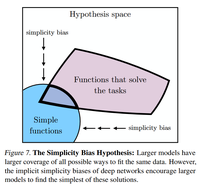

Procesando semillas...
Calculando corte mínimo en el grafo...
Capacidad del corte mínimo: 176
Segmentación finalizada en 4.64 segundos
Costo total del borde: 176.0000
Semillas marcadas: 358 píxeles de Objeto, 244 de Fondo



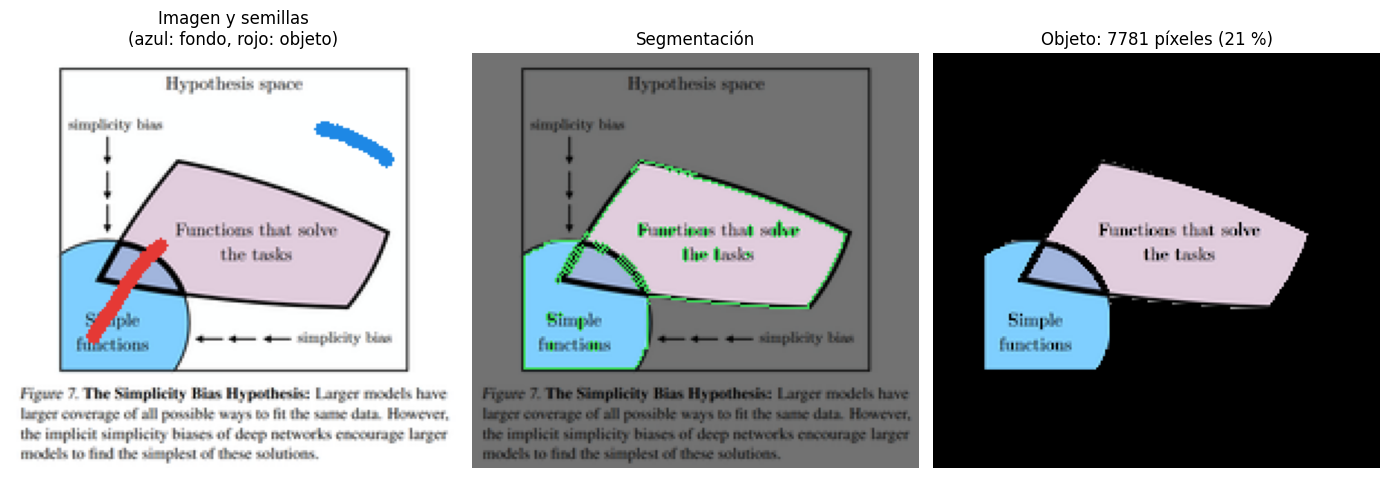

In [ ]:
#Cargamos Imagen
imagen = cargar_imagen(tamano_max=200)

#App interactiva
uid = 'p' + uuid.uuid4().hex[:8]
display(HTML(html_pincel(vista_para_pintar(imagen), uid, trazos_iniciales=[], zoom=3, radio=3)))

#Esperamos promesa
trazos_usuario = output.eval_js(f'esperarTrazos_{uid}()')

#Pasamos a python
print("Procesando semillas...")
semillas_fnd, semillas_obj = trazos_a_semillas(trazos_usuario, imagen.shape[:2])

print("Calculando corte mínimo en el grafo...")
inicio = time.perf_counter()
SIGMA = 30
segmentacion_final = segmentar_con_grafos(imagen, semillas_fnd, semillas_obj, SIGMA)
costo_corte, borde_final = costo_del_borde(imagen, segmentacion_final, SIGMA)
tiempo = time.perf_counter() - inicio

#Metricas
print(f"Segmentación finalizada en {tiempo:.2f} segundos")
print(f"Costo total del borde: {costo_corte:.4f}")
print(f"Semillas marcadas: {semillas_obj.sum()} píxeles de Objeto, {semillas_fnd.sum()} de Fondo\n")

mostrar_resultado(imagen, semillas_fnd, semillas_obj, segmentacion_final, borde_final)

#Parte B: Metodo Mincut Normalizado

En la Parte A, el corte mínimo s-t funcionaba porque alguien marcaba qué era objeto y qué era fondo. Ahora vamos a segmentar sin semillas: la partición tiene que salir solo de la estructura del grafo. Para eso implementamos el método del paper [*Normalized Cuts and Image Segmentation*](https://people.eecs.berkeley.edu/~malik/papers/SM-ncut.pdf), siguiendo sus secciones 2 y 3.

A diferencia del corte mínimo s-t, en este método:

- **No hay semillas, fuente ni sumidero.** La partición se obtiene sin información previa sobre qué píxeles pertenecen a cada región.
- **El criterio a minimizar es el corte normalizado** (Ncut), en vez de resolver el corte mínimo como antes
- **El problema no puede resolverse mediante flujo máximo.** Minimizar Ncut de forma exacta es NP-completo, por lo que se relaja a un problema de autovalores generalizado llegando a una solucion óptima aproximada

Recomendamos leer cada sección del paper antes de la parte correspondiente del notebook, como práctica de lectura de papers. De igual forma, en esta seccion vamos a hacer hincapie en:

| Parte | Sección del paper | Contenido |
|---|---|---|
| B.1 | 2 | Definición de `cut`, `assoc`, `ncut` y `nassoc` (ecuaciones 1 a 3) y análisis de por qué el corte mínimo favorece particiones desbalanceadas (figura 2) |
| B.2 | 2.1 | Verificación numérica de la formulación de Ncut como cociente de Rayleigh (ecuaciones 4 y 5) |
| B.3 | 3.1 | Ejemplo con un conjunto de puntos: construcción de pesos, cálculo de autovectores y partición (figuras 3 a 7) |
| B.4 | 3.2 | Aplicación a imágenes: pesos según la ecuación 15, autovectores sobre matrices dispersas, elección del punto de corte y criterio de estabilidad (figuras 9, 12 y 13) |
| B.5 | 3.3 | Algoritmo de Ncut recursivo (figura 14) |

In [ ]:
def puntos_figura_3(semilla=3):
    '''Un conjunto de puntos como el de la figura 3, numerado como en la figura 4:
    0-89 anillo (en sentido antihorario), 90-99 nube del centro, 100-119 grupo de arriba a la derecha,
    120-139 grupo de abajo a la derecha.'''
    rng = np.random.default_rng(semilla)
    t = np.sort(rng.uniform(0, 2 * np.pi, 90))
    anillo = np.c_[15 * np.cos(t), 15 * np.sin(t)] + rng.normal(0, 1.0, (90, 2))
    centro = rng.normal(0, 1.2, (10, 2))
    arriba = np.array([40, 12]) + rng.normal(0, 2.5, (20, 2))
    abajo = np.array([40, -7]) + rng.normal(0, 2.5, (20, 2))
    return np.r_[anillo, centro, arriba, abajo]

## B.0: Definición de pesos

Antes de definir el criterio de partición es necesario precisar cómo se construye el grafo, porque en Normalized Cuts esta elección cambia respecto del corte mínimo s-t.

### Por qué no alcanza con 4 u 8 vecinos

En el corte mínimo s-t, cada píxel se conectaba solo con sus vecinos inmediatos (4 u 8). Eso era suficiente porque la
información global del problema la aportaban las **semillas**: el corte sabía de antemano
qué colores correspondían al objeto y cuáles al fondo, y las aristas entre vecinos solo regulaban dónde pasaba el borde (o sea, solo servian como "pasaje de informacion")

En Normalized Cuts como no hay semillas la partición tiene que surgir únicamente de la estructura
del grafo (podríamos pensarlo como un problema de topologia y de energia).

Si tuviesemos vecindarios chicos aparecería de nuevo el problema que el criterio Ncut busca evitar. Por ejemplo, si un grupo reducido de píxeles tiene un color distinto al de su entorno, sus pocas aristas (4 u 8 por píxel) tienen peso casi nulo, y aislarlo produce un $\text{Ncut} \approx 0$ (volvemos al problema que intetamos evitar).Dado esto necesitamos vecindarios más grandes.

Una forma de resolver el problema anterior es plantear la distancia euclidiana y trabajar con radio $r$. asi un píxel queda vinculado también con otros más alejados que se le parecen, y separar un grupo exige cortar muchas aristas de peso significativo.


### Definiciones

Cada píxel $n_i$ tiene una posición $\mathbf{X}(n_i) = (f_i, c_i)$ (fila y columna) y un color $\mathbf{I}(n_i) \in [0, 1]^C$, con $C = 3$ en RGB o $C = 1$ en escala de grises.

#### **Distancia (Transformada de la distancia euclideana)**

La distancia entre dos píxeles es la distancia euclídea entre sus posiciones:

$$\text{dist}(n_i, n_j) = \|\mathbf{X}(n_i) - \mathbf{X}(n_j)\|_2 = \sqrt{(f_i - f_j)^2 + (c_i - c_j)^2}$$

<p align="center">
  <img src="https://www.mathworks.com/help/images/dist_xform_euclid.png" width="400">
</p>


#### **Vencidario**

El vecindario de radio $r$ de un píxel es el conjunto de píxeles a distancia menor que $r$:

$$\mathcal{N}_r(n_i) = \{\, n_j \neq n_i \;:\; \text{dist}(n_i, n_j) < r \,\}$$

Contiene aproximadamente $\pi r^2$ píxeles.

Los casos del corte s-t son casos particulares:

- la 4-conectividad corresponde a $1 < r \le \sqrt{2}$

- la 8-conectividad, a $\sqrt{2} < r \le 2$.

#### **Diferencia de color**
La diferencia de color es la distancia euclídea al cuadrado en el espacio de color, sumando sobre los canales:

$$\|\mathbf{I}(n_i) - \mathbf{I}(n_j)\|^2 = \sum_{c=1}^{C} \big(I_c(n_i) - I_c(n_j)\big)^2$$

### El peso de cada arista

$$w(i, j) = \begin{cases}
\exp\left(-\dfrac{\|\mathbf{I}(n_i) - \mathbf{I}(n_j)\|^2}{\sigma_I^2}\right) \cdot \exp\left(-\dfrac{\text{dist}(n_i, n_j)^2}{\sigma_d^2}\right) & \text{si } 0 < \text{dist}(n_i, n_j) < r \\[2ex]
0 & \text{en otro caso}
\end{cases}$$

Esto mide la simulitud de color, la distancia y trunca al vecindario

#### Implementar

In [ ]:
def calcular_peso_entre_pixeles(imagen, pixel_i, pixel_j, sigma_I, sigma_d, r):
    """
    Peso w(i, j) entre dos píxeles.

    imagen: arreglo (H, W, C) con valores en [0, 1]
    pixel_i, pixel_j: tuplas de posiciones (fila, columna)
    sigma_I, sigma_d: escalas de color y de distancia
    r: radio del vecindario
    Devuelve un número en [0, 1].
    """
    # TODO 1: distancia euclídea al cuadrado entre las posiciones
    # TODO 2: si es el mismo píxel, o si la distancia no es estrictamente menor que r, devolver 0
    # TODO 3: diferencia de color al cuadrado, sumada sobre los canales
    # TODO 4: devolver el producto de las dos exponenciales
    raise NotImplementedError('Completar calcular_peso_entre_pixeles')


def calcular_pesos_en_grafo(imagen, radio, sigma_I, sigma_d):
    """
    Matriz de pesos W (n x n), dispersa, con n = H * W.
    Los píxeles se numeran fila por fila: el píxel (f, c) es el nodo k = f * W + c.
    """
    H, W = imagen.shape[:2]
    # TODO 1: lista de desplazamientos (dy, dx) con 0 < dy^2 + dx^2 < radio^2 (alcanza con recorrer dy, dx entre -ceil(radio) y ceil(radio))
    # TODO 2: para cada píxel (f, c) y cada desplazamiento, si el vecino (f + dy, c + dx)  está dentro de la imagen, guardar el nodo de origen, destino y peso.
    # TODO 3: devolver sp.csr_matrix((pesos, (filas, columnas)), shape=(H * W, H * W))
    raise NotImplementedError('Completar calcular_pesos_en_grafo')

#### Tests

In [ ]:
def _peso_referencia(imagen, pi, pj, sig_i, sig_d, r):
    dist_sq = (pi[0] - pj[0])**2 + (pi[1] - pj[1])**2
    if dist_sq == 0 or dist_sq >= r**2: return 0.0
    dif_color_sq = np.sum((imagen[pi[0], pi[1]] - imagen[pj[0], pj[1]])**2)
    return np.exp(-dif_color_sq / sig_i**2) * np.exp(-dist_sq / sig_d**2)

def test_mismo_pixel():
    img = np.zeros((5, 5, 3))
    peso = calcular_peso_entre_pixeles(img, (2, 2), (2, 2), 0.1, 4.0, 5.0)
    assert peso == 0, 'La distancia al mismo píxel es 0, no entra en el vecindario (0 < dist < r)'

def test_fuera_de_radio():
    img = np.zeros((5, 5, 3))
    peso = calcular_peso_entre_pixeles(img, (0, 0), (4, 4), 0.1, 4.0, 3.0)
    assert peso == 0, 'Si la distancia es mayor o igual a r, el peso debe ser 0'

def test_peso_correcto():
    img = np.random.rand(5, 5, 3)
    p1, p2 = (1, 1), (2, 2)
    peso_est = calcular_peso_entre_pixeles(img, p1, p2, 0.1, 4.0, 5.0)
    peso_ref = _peso_referencia(img, p1, p2, 0.1, 4.0, 5.0)
    assert np.isclose(peso_est, peso_ref), f'El cálculo matemático falló. Esperado: {peso_ref:.4f}, Obtenido: {peso_est:.4f}'


pruebas_pesos = [
    ("1. Mismo píxel", test_mismo_pixel),
    ("2. Fuera de radio", test_fuera_de_radio),
    ("3. Matemática del peso", test_peso_correcto)
]

print("Iniciando validación de pesos...\n" + "="*50)
tests_pasados = 0

for nombre, prueba in pruebas_pesos:
    try:
        prueba()
        print(f"{nombre}: Test pasado")
        tests_pasados += 1
    except AssertionError as e:
        print(f"{nombre}: FALLÓ\n   Detalle: {e}")
    except Exception as e:
        print(f"{nombre}: ERROR INESPERADO\n  {type(e).__name__}: {e}")

print("=" * 50)
if tests_pasados == len(pruebas_pesos):
    print("Tu cálculo de pesos es correcto.")
else:
    print("Revisa los errores marcados con antes de graficar.")

Iniciando validación de pesos...
1. Mismo píxel: Test pasado
2. Fuera de radio: Test pasado
3. Matemática del peso: Test pasado
Tu cálculo de pesos es correcto.


#### Visualización

Imagen cargada. Shape: (60, 60, 3)


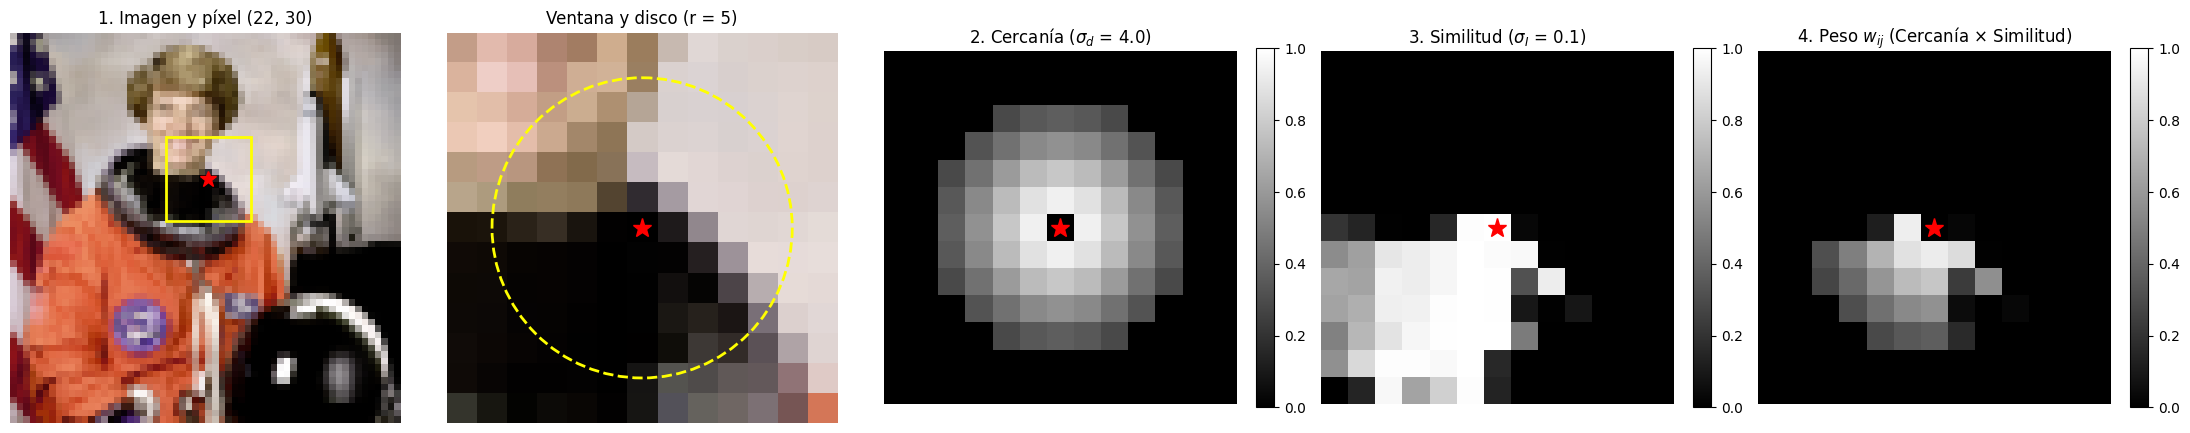

Vecinos dentro del disco: 68
Suma de pesos: solo cercanía = 36.62, total con similitud = 11.92


In [ ]:
def cargar_imagen(ancho=60, subir=False):
    '''Devuelve una imagen RGB achicada a `ancho` columnas, con valores en [0, 1].'''
    if subir:
        from google.colab import files
        datos = np.frombuffer(next(iter(files.upload().values())), np.uint8)
        original = cv2.cvtColor(cv2.imdecode(datos, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    else:
        original = data.astronaut()

    alto = int(round(original.shape[0] * ancho / original.shape[1]))
    return cv2.resize(original, (ancho, alto), interpolation=cv2.INTER_AREA).astype(np.float64) / 255

img = cargar_imagen(ancho=60)
print(f"Imagen cargada. Shape: {img.shape}")

RADIO, SIGMA_I, SIGMA_D = 5, 0.1, 4.0 #Esto totalmente arbritrario, puede usar otros si quieren
pixel = (22, 30) #Si quieren lko pueden cambiar para ubicar otros pixeles

H, W_ = img.shape[:2]
f, c = pixel
v = RADIO + 1
f0, f1 = max(0, f - v), min(H, f + v + 1)
c0, c1 = max(0, c - v), min(W_, c + v + 1)
ext = (c0 - 0.5, c1 - 0.5, f1 - 0.5, f0 - 0.5)

#Coordenadas de cada pixel
filas, cols = np.mgrid[f0:f1, c0:c1]
dist = np.sqrt((filas - f) ** 2 + (cols - c) ** 2)
vecino = (dist > 0) & (dist < RADIO)

#Mascara de cercanica
cercania = np.where(vecino, np.exp(-dist ** 2 / SIGMA_D ** 2), 0)

#Mascara de similitud
dif_color = np.linalg.norm(img[f0:f1, c0:c1] - img[f, c], axis=-1)
similitud = np.exp(-dif_color ** 2 / SIGMA_I ** 2)

#Peso final de las aristas
peso = cercania * similitud

#GRAFICOS
fig, axs = plt.subplots(1, 5, figsize=(22, 4.5))

axs[0].imshow(img)
axs[0].plot(c, f, 'r*', ms=12)
axs[0].add_patch(plt.Rectangle((c0 - 0.5, f0 - 0.5), c1 - c0, f1 - f0, fill=False, ec='yellow', lw=2))
axs[0].set_title(f'1. Imagen y píxel {pixel}')

axs[1].imshow(img[f0:f1, c0:c1], extent=ext)
axs[1].plot(c, f, 'r*', ms=14)
axs[1].add_patch(plt.Circle((c, f), RADIO, fill=False, ec='yellow', lw=2, ls='--'))
axs[1].set_title(f'Ventana y disco (r = {RADIO})')

paneles = [
    (cercania, f'2. Cercanía ($\\sigma_d$ = {SIGMA_D})'),
    (similitud, f'3. Similitud ($\\sigma_I$ = {SIGMA_I})'),
    (peso, '4. Peso $w_{ij}$ (Cercanía × Similitud)')
]

for ax, (mapa, titulo) in zip(axs[2:], paneles):
    im = ax.imshow(mapa, cmap='gray', vmin=0, vmax=1, extent=ext)
    ax.plot(c, f, 'r*', ms=14)
    ax.set_title(titulo)
    plt.colorbar(im, ax=ax, fraction=0.046)

for a in axs: a.axis('off')

plt.tight_layout()
plt.show()

print(f'Vecinos dentro del disco: {vecino.sum()}')
print(f'Suma de pesos: solo cercanía = {cercania.sum():.2f}, total con similitud = {peso.sum():.2f}')

##B.1 Definiciones matematicas (sección 2)

Para una partición $V = A \cup B$ de los nodos, se definen las siguiente definiciones:

$$\text{cut}(A, B) = \sum_{u \in A,\, v \in B} w(u, v), \qquad \text{assoc}(A, V) = \sum_{u \in A,\, t \in V} w(u, t)$$

Donde:
- $\text{cut}(A, B)$ es el valor del corte de las aristas que conectan a las particiones $A$ y $B$

- $\text{assoc}(A, V)$ es el valor de las aristas de la particion $A$ con todos las aristas del grafo.
  - $\text{assoc}(A, A)$: la conexión de $A$ consigo mismo, es decir, qué tan unido está internamente.


Se cumple que $\text{assoc}(A, V) = \text{assoc}(A, A) + \text{cut}(A, B)$: la conexión de $A$ se reparte entre las
aristas que quedan adentro y las que cruzan.

A partir de estas definiciones se definen el **corte normalizado** y la **asociación normalizada**:

$$\text{Ncut}(A, B) = \frac{\text{cut}(A, B)}{\text{assoc}(A, V)} + \frac{\text{cut}(A, B)}{\text{assoc}(B, V)}$$

$$\text{Nassoc}(A, B) = \frac{\text{assoc}(A, A)}{\text{assoc}(A, V)} + \frac{\text{assoc}(B, B)}{\text{assoc}(B, V)}$$



A diferencia del corte mínimo clásico, Ncut penaliza las particiones donde un conjunto es muy pequeño (como un solo píxel), ya que su $\text{assoc}$ en el denominador será diminuto, disparando el costo de Ncut.

Además minimizar el corte entre grupos y maximizar la asociación dentro de cada grupo son el mismo problema. Dado la relacion:

$$\text{Ncut}(A, B) = 2 - \text{Nassoc}(A, B)$$


**Ejercicio:** Completa las funciones vectorizadas a continuación. Las matrices `W` pueden ser `numpy.ndarray` o dispersas (`scipy.sparse.csr_matrix`), así que apóyate en indexación booleana.


Para una partición $V = A \cup B$ de los nodos, el paper introduce las siguientes métricas:

*   **$\text{cut}(A, B) = \sum_{u \in A,\, v \in B} w(u, v)$**: La suma de los pesos de las aristas que se rompen al separar $A$ y $B$.
*   **$\text{assoc}(A, V) = \sum_{u \in A,\, t \in V} w(u, t)$**: La conexión total de los nodos de $A$ con todo el grafo (grado).
*   **$\text{assoc}(A, A)$**: La conexión interna de $A$ consigo mismo.

A partir de esto, se definen el **Corte Normalizado (Ncut)** y la **Asociación Normalizada (Nassoc)**:

$$\text{Ncut}(A, B) = \frac{\text{cut}(A, B)}{\text{assoc}(A, V)} + \frac{\text{cut}(A, B)}{\text{assoc}(B, V)}$$

$$\text{Nassoc}(A, B) = \frac{\text{assoc}(A, A)}{\text{assoc}(A, V)} + \frac{\text{assoc}(B, B)}{\text{assoc}(B, V)}$$

A diferencia del corte mínimo clásico, Ncut penaliza las particiones donde un conjunto es muy pequeño (como un solo píxel), ya que su $\text{assoc}$ en el denominador será diminuto, disparando el costo de Ncut.

**Ejercicio:** Completa las funciones vectorizadas a continuación. Las matrices `W` pueden ser `numpy.ndarray` o dispersas (`scipy.sparse.csr_matrix`), así que apóyate en indexación booleana.

### Ejercicio Implementar las funciones assoc, ncut y nassoc

In [ ]:
def cut(W, A):
    """
    Suma de los pesos de las aristas que cruzan entre A y ~A.
    W: matriz de pesos (n x n)
    A: arreglo booleano de longitud n indicando pertenencia a la partición A.
    """
    # W[A, :][:, ~A] hace dos extracciones:
    #   1) W[A, :]   → primero extraemos las filas de A.
    #   2) [:, ~A]   → de esas filas, nos quedamos con las columnas que
    #                  NO están en A.
    # El resultado es la submatriz de aristas del corte (A → ~A);
    # luego solo hay que sumar todos sus elementos.
    if sp.issparse(W):
        return W[A, :][:, ~A].sum()
    return W[A][:, ~A].sum()


def assoc(W, A, B=None):
    """
    Suma de las conexiones de los nodos de A hacia el conjunto B.
    Si B no se provee, calcula assoc(A, V) (conexión a todos los nodos).
    """
    if B is None:
        if sp.issparse(W):
            return W[A, :].sum()
        return W[A].sum()

    # TODO: Implementar el caso cuando B sí es provisto (es decir, assoc(A, B))
    raise NotImplementedError('Completar assoc(A, B)')


def ncut(W, A):
    """
    Calcula el Normalized Cut para la partición (A, ~A).
    Si A o ~A están vacíos, devuelve np.inf.
    """
    if not A.any() or A.all():
        return np.inf

    # TODO: Calcular y devolver Ncut usando las funciones cut() y assoc()
    raise NotImplementedError('Completar Ncut')


def nassoc(W, A):
    """
    Calcula la Normalized Association para la partición (A, ~A).
    """
    if not A.any() or A.all():
        return 0.0

    # TODO: Calcular y devolver Nassoc usando la función assoc()
    raise NotImplementedError('Completar Nassoc')

### Tests

In [ ]:
def test_calculos_basicos_grafo_pequeno():
    # Grafo 4 nodos: 0-1 unidos fuerte (5), 2-3 unidos fuerte (5)
    # 1-2 y 0-3 unidos débil (1)
    W4 = np.zeros((4, 4))
    for i, j, w in [(0, 1, 5), (2, 3, 5), (1, 2, 1), (0, 3, 1)]:
        W4[i, j] = W4[j, i] = w

    A = np.array([True, True, False, False]) # Separa {0,1} de {2,3}

    assert np.isclose(cut(W4, A), 2), f"cut({A}) = w12 + w03 = 2"
    assert np.isclose(assoc(W4, A), 12), "assoc(A, V) debe ser grado(0) + grado(1) = 6 + 6 = 12"
    assert np.isclose(assoc(W4, A, A), 10), "assoc(A, A) debe ser w01 + w10 = 5 + 5 = 10"
    assert np.isclose(ncut(W4, A), 2/12 + 2/12), "Cálculo de Ncut fallido"

def test_matriz_dispersa_csr():
    W4 = np.zeros((4, 4))
    for i, j, w in [(0, 1, 5), (2, 3, 5), (1, 2, 1), (0, 3, 1)]:
        W4[i, j] = W4[j, i] = w
    W_sparse = sp.csr_matrix(W4)
    A = np.array([True, True, False, False])
    assert np.isclose(ncut(W_sparse, A), ncut(W4, A)), 'Tiene que andar con matrices dispersas (csr_matrix)'

def test_teorema_ncut_nassoc():
    """Prueba numérica de que Ncut(A,B) = 2 - Nassoc(A,B)"""
    W4 = np.random.rand(4, 4)
    W4 = (W4 + W4.T) / 2

    A = np.array([True, False, True, False])
    assert np.isclose(ncut(W4, A), 2 - nassoc(W4, A)), 'La identidad teórica Ncut = 2 - Nassoc no se cumple'

pruebas_ncut = [
    ("1. Cálculos de cut y assoc", test_calculos_basicos_grafo_pequeno),
    ("2. Soporte para matrices dispersas", test_matriz_dispersa_csr),
    ("3. Identidad: Ncut = 2 - Nassoc", test_teorema_ncut_nassoc),
]

print("Iniciando validación matemática de Ncut...\n" + "="*50)
tests_pasados = 0

for nombre, prueba in pruebas_ncut:
    try:
        prueba()
        print(f"{nombre}: Test Pasado")
        tests_pasados += 1
    except AssertionError as e:
        print(f"{nombre}: FALLÓ\n  Detalle: {e}")
    except Exception as e:
        print(f"{nombre}: ERROR INESPERADO\n  {type(e).__name__}: {e}")

print("=" * 50)
if tests_pasados == len(pruebas_ncut):
    print("Tus métricas matemáticas funcionan perfectamente")

Iniciando validación matemática de Ncut...
1. Cálculos de cut y assoc: Test Pasado
2. Soporte para matrices dispersas: Test Pasado
3. Identidad: Ncut = 2 - Nassoc: Test Pasado
Tus métricas matemáticas funcionan perfectamente


### Por qué el corte mínimo falla (Figura 2 del paper)

Recreemos el problema visual que motiva el uso de Ncut. Armamos una "nube" densa de puntos a la izquierda y unos pocos puntos dispersos a la derecha.

Comparamos tres estrategias de corte:
1. Aislar un punto del extremo izquierdo (Corte Mínimo a veces elige esto).
2. Aislar un punto del extremo derecho (Corte Mínimo suele elegir esto porque corta menos aristas).
3. Cortar por el medio (Agrupamiento ideal para humanos, y el mínimo bajo el criterio de Ncut).

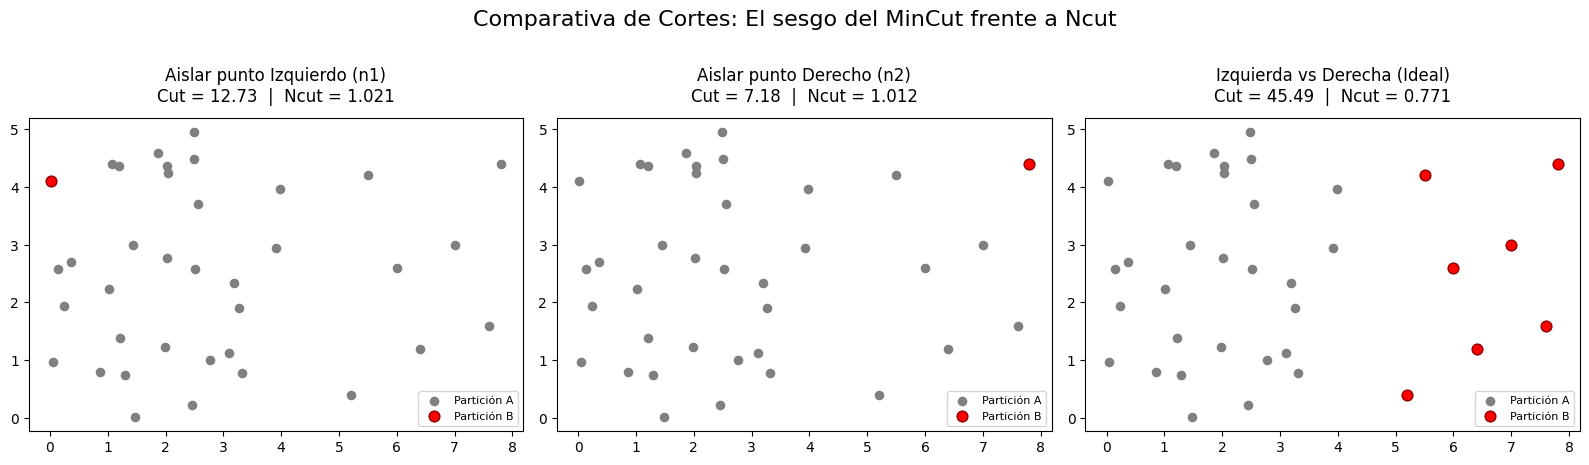

In [ ]:
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)


izq = rng.uniform([0, 0], [4, 5], (30, 2))
der = np.array([[5.5, 4.2], [6.4, 1.2], [7.0, 3.0], [6.0, 2.6], [5.2, 0.4], [7.6, 1.6], [7.8, 4.4]])
P2 = np.r_[izq, der]

# Pesos inversamente proporcionales a la distancia euclídea
dist = np.linalg.norm(P2[:, None] - P2[None], axis=-1)
W2 = np.where(dist > 0, 1 / np.maximum(dist, 1e-9), 0)

# Elegimos dos nodos extremos para aislar
n1 = 3
n2 = -1

particiones = {
    'Aislar punto Izquierdo (n1)': np.arange(len(P2)) == n1,
    'Aislar punto Derecho (n2)': np.arange(len(P2)) == len(P2) + n2,
    'Izquierda vs Derecha (Ideal)': np.arange(len(P2)) >= len(izq)
}

fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (nombre, Ap) in zip(axs, particiones.items()):
    ax.scatter(*P2[~Ap].T, c='gray', s=35, label='Partición A')
    ax.scatter(*P2[Ap].T, c='red', s=60, edgecolors='darkred', label='Partición B')

    corte_val = cut(W2, Ap)
    ncut_val = ncut(W2, Ap)

    ax.set_title(f'{nombre}\nCut = {corte_val:.2f}  |  Ncut = {ncut_val:.3f}', fontsize=12, pad=12)
    ax.set_aspect('equal')
    ax.legend(loc='lower right', fontsize=8)

plt.suptitle("Comparativa de Cortes: El sesgo del MinCut frente a Ncut", fontsize=16, y=1.05)
plt.tight_layout()
plt.show()

## B.2 La Matemática del Corte Normalizado (Sección 2.1)

La sección 2.1 del paper reescribe el problema de Ncut utilizando un vector indicador $\mathbf{x}$ (donde $x_i = 1$ si el nodo pertenece al conjunto $A$, y $x_i = -1$ si pertenece a $B$). Mediante álgebra, los autores demuestran que minimizar Ncut equivale a:

$$
\min_{\mathbf{x}} \text{Ncut}(\mathbf{x}) = \min_{\mathbf{y}} \frac{\mathbf{y}^T(\mathbf{D} - \mathbf{W})\mathbf{y}}{\mathbf{y}^T \mathbf{D}\mathbf{y}} \qquad \text{sujeto a} \quad y_i \in \{1, -b\} \quad \text{y} \quad \mathbf{y}^T\mathbf{D}\mathbf{1} = 0
$$

**¿Qué son estas variables?**
*   **$\mathbf{D} = \text{diag}(d_1, \dots, d_n)$**: Matriz diagonal donde cada $d_i = \sum_j w(i, j)$ es el grado del nodo $i$.
*   **$k = \frac{\sum_{x_i > 0} d_i}{\sum_i d_i}$**: La fracción del grado total del grafo que quedó dentro de la partición $A$.
*   **$b = \frac{k}{1 - k}$**: Constante que garantiza que se cumpla la restricción $\mathbf{y}^T\mathbf{D}\mathbf{1} = 0$.
*   **$\mathbf{y} = (\mathbf{1} + \mathbf{x}) - b(\mathbf{1} - \mathbf{x})$**: Un vector transformado que toma el valor $2$ en los nodos de $A$ y $-2b$ en los de $B$. (En el paper se divide por 2 para que $y_i \in \{1, -b\}$).

Esta igualdad es matemáticamente exacta. Sin embargo, minimizar esta función limitando $\mathbf{y}$ a tomar **solo valores discretos** $\{1, -b\}$ es un problema NP-completo.

## B.3 La Relajación Espectral (Sección 2.1)

Como el problema discreto es intratable en imágenes reales, aplicamos una **relajación espectral**. O sea, Permitimos que el vector $\mathbf{y}$ tome cualquier valor real, manteniendo la restricción de ortogonalidad $\mathbf{y}^T\mathbf{D}\mathbf{1} = 0$.

Al hacer esto, abandonamos el problema original discreto y resolvemos una aproximación. Pero ganamos ahora la resolucion se puede realizar porque se conoce la respuesta a minimizar ese cociente de Rayleigh continuo

La solución óptima $\mathbf{y}$ resulta ser un **autovector** del problema de autovalores generalizado:

$$(\mathbf{D} - \mathbf{W})\,\mathbf{y} = \lambda\, \mathbf{D}\, \mathbf{y}$$

Donde la matriz $(\mathbf{D} - \mathbf{W})$ se conoce como el **Laplaciano del Grafo**.

#### **El primer autovector (Trivial)**
El autovector más pequeño siempre es el vector de unos constantes, $\mathbf{y}_0 = \mathbf{1}$, cuyo autovalor es $\lambda_0 = 0$.
*(Demostración rápida: si la fila de $\mathbf{W}$ suma $d_i$, entonces la fila correspondiente de $\mathbf{D} - \mathbf{W}$ suma cero, por lo que multiplicarla por un vector de unos da el vector nulo).*
Sin embargo, este vector $\mathbf{y}_0$ no nos sirve para segmentar, ya que no cumple la restricción $\mathbf{y}^T\mathbf{D}\mathbf{1} = 0$.

#### **El segundo autovector (La solución)**
El vector que buscamos es **$\mathbf{y}_1$**, el autovector asociado al **segundo autovalor más pequeño** ($\lambda_1$), también conocido como el *Vector de Fiedler*.

Para calcularlo eficientemente usando herramientas matemáticas estándar, el paper aplica un cambio de variable $\mathbf{y} = \mathbf{D}^{-1/2}\mathbf{z}$ para convertir el problema generalizado en un problema de autovalores simétrico estándar con los mismos autovalores (Ecuación 7):

$$\mathbf{D}^{-1/2}(\mathbf{D} - \mathbf{W})\mathbf{D}^{-1/2}\, \mathbf{z} = \lambda\, \mathbf{z}$$

#### **Volviendo a la partición discreta**
Dado que relajamos el problema, los valores de nuestro autovector $\mathbf{y}_1$ serán números reales continuos (ej: $0.4, -0.1, 0.8 \dots$).
Para convertirlos nuevamente en una máscara binaria de segmentación ($A$ vs $B$), debemos elegir un **punto de corte (umbral)**: los píxeles cuyo valor en $\mathbf{y}_1$ sea mayor al umbral irán al objeto, y el resto al fondo.

## B.3 Ejemplo de Juguete: Conjunto de Puntos en 2D (Sección 3.1)

Antes de lidiar con los millones de píxeles de una imagen real, vamos a reproducir el ejemplo de la **Figura 3 del paper** original de Shi y Malik.

Tenemos 140 puntos en 2D distribuidos en cuatro grupos:
1. Un anillo denso (90 puntos).
2. Un centro disperso (10 puntos).
3. Un grupo arriba a la derecha (20 puntos).
4. Un grupo abajo a la derecha (20 puntos).

**Pensá intuitivamente:**
*   Si tuvieras que separarlos en dos grandes grupos, ¿por dónde trazarías la línea?
*   ¿Y si fueran cuatro grupos?
*   Recordá la fórmula de Ncut: ¿qué corte minimiza las aristas rotas pero mantiene un buen "volumen" de grado en ambas mitades?


In [ ]:
def puntos_figura_3():
    rng = np.random.default_rng(42)
    theta = rng.uniform(0, 2*np.pi, 90)
    r = rng.uniform(8, 10, 90)
    anillo = np.c_[r*np.cos(theta), r*np.sin(theta)]
    centro = rng.normal(0, 1.5, (10, 2))
    arriba = rng.normal([18, 8], 1.5, (20, 2))
    abajo = rng.normal([18, -8], 1.5, (20, 2))
    return np.r_[anillo, centro, arriba, abajo]

In [ ]:
P = puntos_figura_3()
grupos_reales = np.repeat([0, 1, 2, 3], [90, 10, 20, 20])

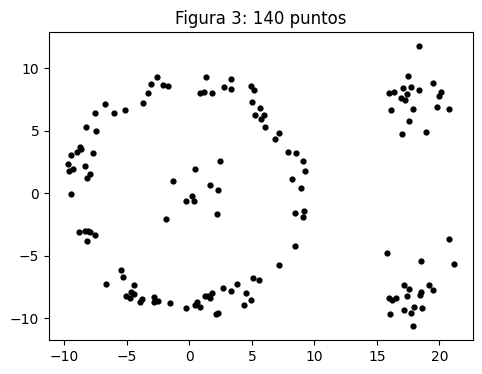

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(*P.T, s=12, c='k'); plt.gca().set_aspect('equal')
plt.title('Figura 3: 140 puntos'); plt.show()

#### PASO 1: Creamos la matriz de pesos

Cada punto es un nodo y cada par de puntos se conecta con una arista. Es lo mismo que hicimos con los píxeles, pero sin color: el peso depende solo de la distancia,

$$w(i, j) = e^{-d(i, j) / \sigma_x}, \qquad \sigma_x = 2,$$

con $d(i, j)$ la distancia euclídea.
Como son solo 140 puntos, conectamos **todos con todos** (sin radio) y guardamos $W$ como matriz densa de $140 \times 140$.


In [ ]:
def pesos_puntos(P, sigma_x=2.0):
    """
    Calcula la matriz de pesos espaciales para un conjunto de puntos.
    W_{ij} = e^{-d(i, j) / sigma_x}
    """
    #Calculá la distancia euclídea entre todos los pares de puntos.
    # Ayuda: P[:, None, :] - P[None, :, :] te da las diferencias.
    # Usá np.linalg.norm con axis=-1.

    #Calculá W usando la exponencial.

    #Hacé que la diagonal sea 0 (usá np.fill_diagonal)
    #y devolvé W.
    raise NotImplementedError('Completar pesos_puntos')

In [ ]:
try:
    Wp = pesos_puntos(P, 2.0)
    assert Wp.shape == (140, 140), 'W tiene que ser de 140 x 140'
    assert np.allclose(Wp, Wp.T), 'W tiene que ser perfectamente simétrica'
    assert np.allclose(np.diag(Wp), 0), 'La diagonal tiene que ser 0'

    dist_prueba = np.linalg.norm(np.array([0., 0.]) - np.array([3., 4.])) # Distancia = 5
    assert np.isclose(pesos_puntos(np.array([[0., 0], [3, 4]]), 2.0)[0, 1], np.exp(-5 / 2.0)), 'Cálculo exponencial incorrecto'
    print("pesos_puntos: OK")
except Exception as e:
    print(f"Error en pesos_puntos: {e}")

pesos_puntos: OK


### PASO 2: Calculamos la Relajación (Autovectores)

Necesitamos resolver el sistema generalizado $(\mathbf{D} - \mathbf{W})\mathbf{y} = \lambda\mathbf{D}\mathbf{y}$.
Como vimos, la forma estable de hacer esto en Python es convertirlo al problema simétrico estándar:

1. Calcular la diagonal de grados $\mathbf{d}$ y su inversa de la raíz cuadrada $\mathbf{s} = \mathbf{d}^{-1/2}$.
2. Armar la matriz Laplaciana Normalizada: $\mathbf{M} = \mathbf{I} - \mathbf{D}^{-1/2}\mathbf{W}\mathbf{D}^{-1/2}$.
3. Extraer los autovalores y autovectores de $\mathbf{M}$ (usando `np.linalg.eigh`, que está optimizado para matrices simétricas).
4. Transformar los autovectores $\mathbf{z}$ de vuelta al espacio original: $\mathbf{y} = \mathbf{D}^{-1/2}\mathbf{z}$.

In [ ]:
def autovectores(W, n):
    """
    Devuelve los n autovalores más chicos y sus respectivos autovectores (y).
    Retorna: (lam, Y) donde Y es una matriz con los autovectores como columnas.
    """
    # TODO 1: Calculá los grados (d) sumando las filas de W.
    # Calculá s = 1.0 / np.sqrt(d)

    # TODO 2: Construí M = I - (D^-1/2 W D^-1/2)
    # Ayuda: La multiplicación matricial diagonal D^-1/2 W D^-1/2 en NumPy
    # se puede hacer vectorizada con broadcasting: s[:, None] * W * s[None, :]
    # La identidad la obtenés con np.eye(len(W))

    # TODO 3: Obtené TODOS los autovalores (lam) y autovectores (Z) usando np.linalg.eigh(M)

    # TODO 4: Transformá Z en Y multiplicando las filas de Z por s (s[:, None] * Z)
    # Devolvé solo los primeros n autovalores y las primeras n columnas de Y.
    raise NotImplementedError('Completar autovectores')

In [ ]:
try:
    lam, Y = autovectores(Wp, 10)
    Dp = np.diag(Wp.sum(1))

    assert lam.shape == (10,) and Y.shape == (140, 10), 'Dimensiones incorrectas'
    assert np.all(np.diff(lam) >= -1e-12), 'Los autovalores no están ordenados de menor a mayor'

    k = 1
    left_side = (Dp - Wp) @ Y[:, k]
    right_side = lam[k] * Dp @ Y[:, k]
    assert np.allclose(left_side, right_side, atol=1e-8), f'Y[:, {k}] no cumple (D - W) y = λ D y'

    assert np.isclose(lam[0], 0, atol=1e-10) and np.allclose(Y[:, 0], Y[0, 0]), 'y_0 tiene que ser constante con λ = 0'
    assert abs(Y[:, 1] @ Wp.sum(1)) < 1e-8, 'y_1 tiene que cumplir que y^T D 1 = 0'

    print("autovectores: OK")
except Exception as e:
    print(f"Error en autovectores: {e}")

autovectores: OK


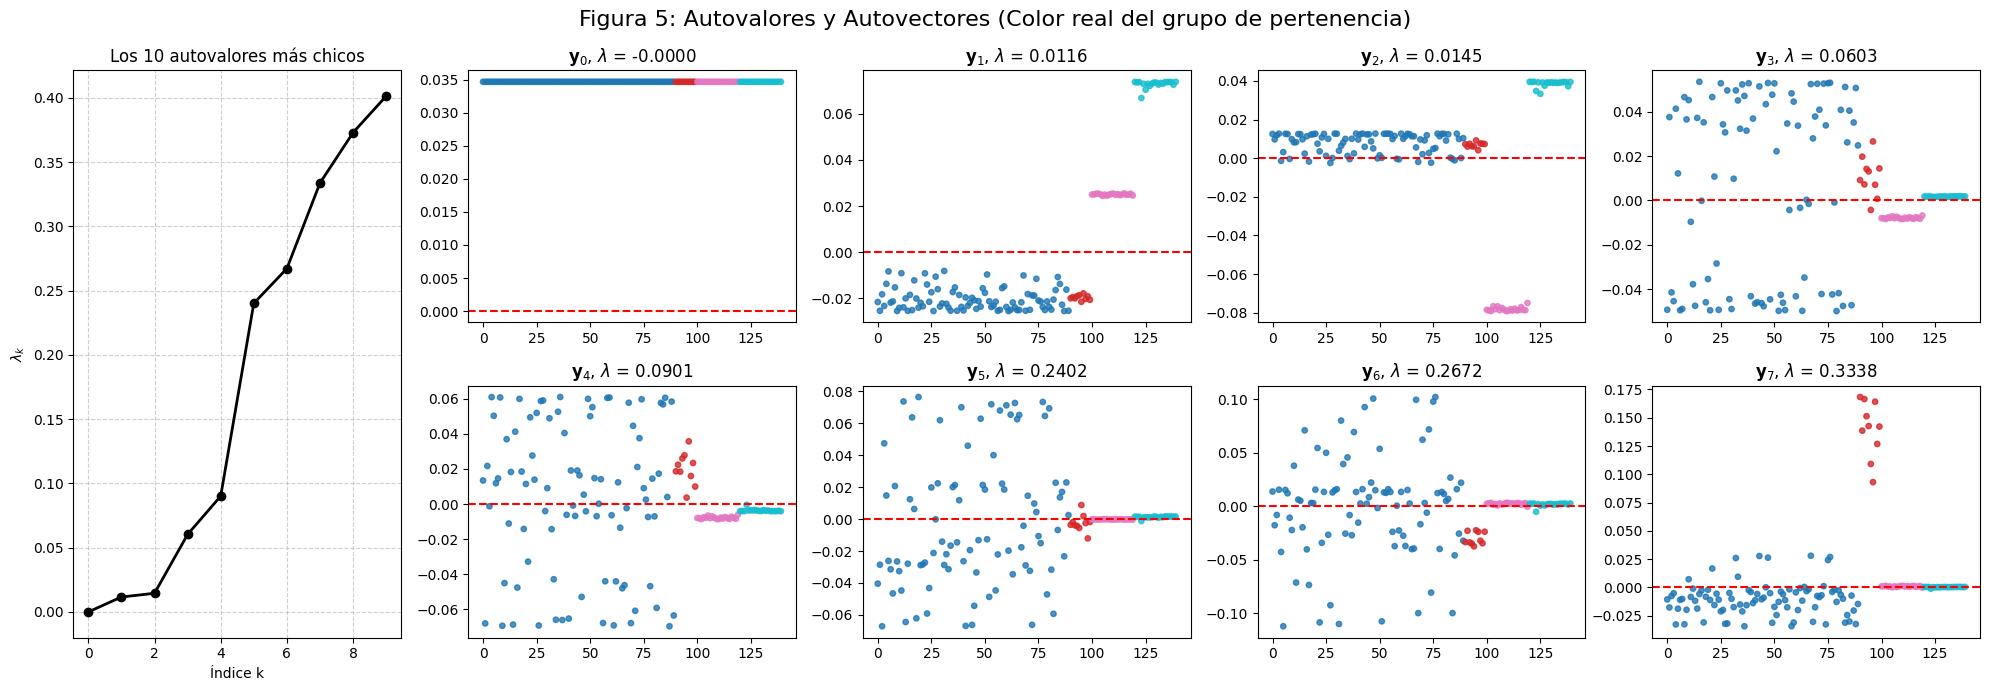

In [ ]:
fig = plt.figure(figsize=(20, 7))
ax = fig.add_subplot(2, 5, (1, 6))
ax.plot(range(10), lam, 'ko-', lw=2)
ax.set_xlabel('Índice k'); ax.set_ylabel(r'$\lambda_k$'); ax.set_title('Los 10 autovalores más chicos')
ax.grid(True, linestyle='--', alpha=0.6)

for k in range(8):
    ax = fig.add_subplot(2, 5, [2, 3, 4, 5, 7, 8, 9, 10][k])
    ax.scatter(range(140), Y[:, k], c=grupos_reales, cmap='tab10', s=15, alpha=0.8)
    ax.axhline(0, color='red', lw=1.5, linestyle='--')
    ax.set_title(f'$\\mathbf{{y}}_{k}$, $\\lambda$ = {lam[k]:.4f}', fontsize=12)

fig.suptitle('Figura 5: Autovalores y Autovectores (Color real del grupo de pertenencia)', fontsize=16)
plt.tight_layout()
plt.show()

Partimos heuristicamente en y_1

Partición heurística (y_1 > 0): A tiene 40 puntos, B tiene 100 puntos
Ncut del corte heurístico: 0.0139


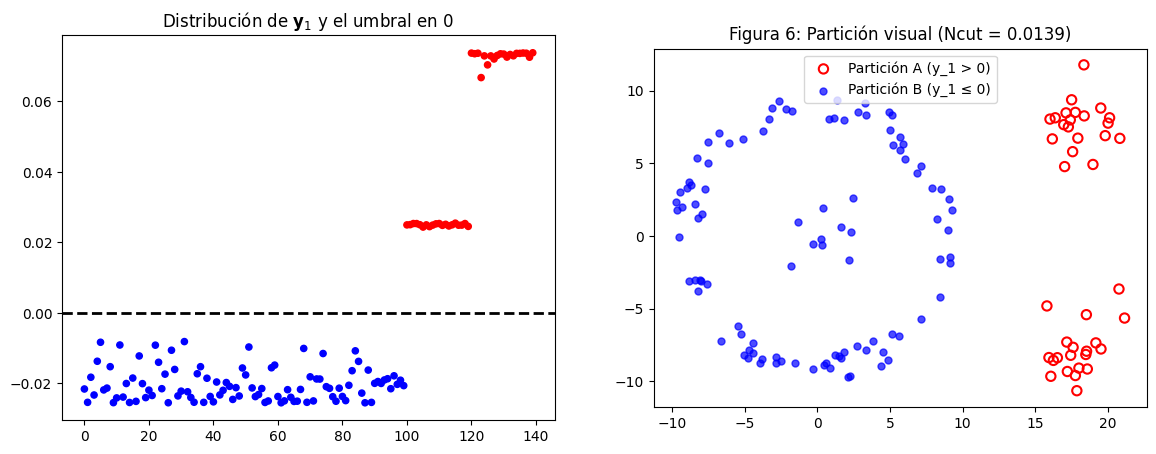

In [ ]:
y1 = Y[:, 1]
A = y1 > 0
print(f'Partición heurística (y_1 > 0): A tiene {A.sum()} puntos, B tiene {(~A).sum()} puntos')
print(f'Ncut del corte heurístico: {ncut(Wp, A):.4f}')

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
axs[0].scatter(range(140), y1, c=np.where(A, 'red', 'blue'), s=20)
axs[0].axhline(0, color='black', lw=2, linestyle='--')
axs[0].set_title(r'Distribución de $\mathbf{y}_1$ y el umbral en 0')

axs[1].scatter(*P[A].T, edgecolors='red', facecolors='none', s=45, lw=1.5, label='Partición A (y_1 > 0)')
axs[1].scatter(*P[~A].T, c='blue', s=25, alpha=0.7, label='Partición B (y_1 ≤ 0)')
axs[1].set_aspect('equal')
axs[1].set_title(f'Figura 6: Partición visual (Ncut = {ncut(Wp, A):.4f})')
axs[1].legend()
plt.show()

Vean que:
- $\mathbf{y}_0$ es **constante** con $\lambda_0 = 0$: no separa nada, como vimos en la Parte 2.
- $\mathbf{y}_1$ toma **solo dos valores**: uno en los puntos 0-99 y otro en los 100-139. Es casi un indicador discreto (O sea, a relajación casi no perdió nada y los podemos separar mediante algun tipo de umbral).

- $\lambda_1$ también es casi 0. Como $\lambda$ es el valor del cociente de Rayleigh, eso significa que existe una  partición con Ncut casi 0: el grafo está casi desconectado en dos partes.

- Los siguientes también separan grupos (por ejemplo, $\mathbf{y}_2$ separa los dos grupos de la derecha. Mientras que $\mathbf{y}_4$ separa a los grudpos de la izquierda).



### Parte 3: Optimizando el Corte (El Mejor Umbral)

Cortar en 0 es una regla rápida y funcionó muy bien para separar la izquierda de la derecha con $\mathbf{y}_1$. Pero, ¿qué pasa si analizamos $\mathbf{y}_4$?
En los gráficos superiores vemos que $\mathbf{y}_4$ toma valores muy negativos para el centro, y cercanos a cero o positivos para el anillo.

El paper propone como solución:
1. Probar $l$ umbrales equiespaciados entre el valor mínimo y máximo del autovector en el grupo actual.
2. Calcular el valor de `Ncut` para cada uno.
3. Quedarse con el umbral que produzca el **menor Ncut**.

In [ ]:
def mejor_umbral(W, y, l=30):
    """
    Busca el umbral de corte sobre 'y' que minimice el Ncut.
    Devuelve: (umbral_optimo, ncut_minimo, lista_umbrales, lista_valores_ncut)
    """
    #Creá un vector con 'l' umbrales equiespaciados, ESTRICTAMENTE entre y.min() y y.max(). (Si tomás los extremos, una partición quedará vacía).
    # Ayuda: np.linspace(y.min(), y.max(), l + 2)[1:-1]

    # Iterá sobre esos umbrales, calculá la máscara booleana A = (y > u) y calculá su valor ncut(W, A). Guardalos en un vector o lista.

    #Encontrá el índice del mínimo valor de Ncut.
    # Devolvé: el mejor umbral, el menor ncut, la lista de umbrales, la lista de valores.
    raise NotImplementedError('Completar mejor_umbral')

In [ ]:
try:
    u_opt, nc_opt, umbrales, valores = mejor_umbral(Wp, Y[:, 1], l=30)
    assert len(umbrales) == 30, 'Debe haber 30 umbrales de prueba'
    assert min(umbrales) > Y[:, 1].min() and max(umbrales) < Y[:, 1].max(), 'No incluir los extremos absolutos'
    assert u_opt == umbrales[np.argmin(valores)], 'El umbral devuelto no es el del Ncut mínimo'
    print(f"mejor_umbral: OK. El mejor corte para y_1 se da en el umbral: {u_opt:.4f}")
except Exception as e:
    print(f"Error en mejor_umbral: {e}")

mejor_umbral: OK. El mejor corte para y_1 se da en el umbral: 0.0258


Veamos que pasa al subdividir los grupos mediante los mejores autovectores que separan los grupos

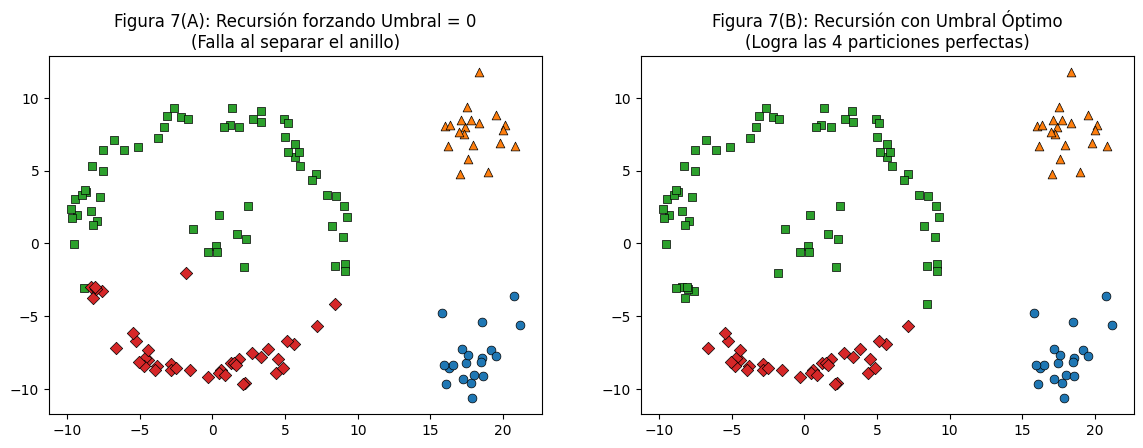

In [ ]:
def subdividir(W, Y, grupo_mask, autovectores_a_probar, func_umbral):
    """Aplica la partición recursiva en un subgrafo dado."""
    idx = np.nonzero(grupo_mask)[0]
    W_g = W[np.ix_(idx, idx)] # Subgrafo

    mejor = None
    for k in autovectores_a_probar:
        y_g = Y[idx, k]
        umbral_aplicado = func_umbral(W_g, y_g)
        lado = y_g > umbral_aplicado
        nc = ncut(W_g, lado)
        if mejor is None or nc < mejor[3]:
            mejor = (idx[lado], idx[~lado], k, nc)
    return mejor

func_cero = lambda W, y: 0.0
partes_cero = []
for grupo in [A, ~A]:
    partes_cero += subdividir(Wp, Y, grupo, [2, 3, 4], func_cero)[:2]


func_optima = lambda W, y: mejor_umbral(W, y)[0]
partes_opt = []
for grupo in [A, ~A]:
    partes_opt += subdividir(Wp, Y, grupo, [2, 3, 4], func_optima)[:2]

def dibujar_subdivision(ax, partes, titulo):
    markers = ['o', '^', 's', 'D']
    colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
    for parte, m, c in zip(partes, markers, colors):
        ax.scatter(*P[parte].T, marker=m, color=c, s=40, edgecolor='k', linewidth=0.5)
    ax.set_aspect('equal')
    ax.set_title(titulo)

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
dibujar_subdivision(axs[0], partes_cero, 'Figura 7(A): Recursión forzando Umbral = 0\n(Falla al separar el anillo)')
dibujar_subdivision(axs[1], partes_opt, 'Figura 7(B): Recursión con Umbral Óptimo\n(Logra las 4 particiones perfectas)')
plt.show()

## B.4 Grafos Gigantes: El problema de la Memoria (Sección 3.2)

Hasta ahora resolvimos un problema con 140 puntos. Pero una imagen pequeña de $80 \times 100$ píxeles tiene $8,000$ nodos. Una matriz de adyacencia densa para esa imagen tendría $64,000,000$ de elementos. Computar los autovectores ahí sería extremadamente lento.

Afortunadamente, nuestra matriz $W$ es **dispersa (sparse)**: como impusimos un radio máximo $r$ (VEAN LA PARTE 0 DE NOTEBOOK), la gran mayoría de las conexiones son cero.

Para matrices dispersas simétricas, el método de Lanczos (`scipy.sparse.linalg.eigsh`) es ideal. Sin embargo, tiene una particularidad: **encuentra mucho más rápido los autovalores más grandes que los más chicos**.

El paper resuelve esto con una manipulación algebraica brillante (Ecuación 14):
$$\mathbf{D}^{-1/2}\mathbf{W}\mathbf{D}^{-1/2}\, \mathbf{z} = (1 - \lambda)\, \mathbf{z}$$

Si llamamos $\mu = 1 - \lambda$, entonces buscar los $\lambda$ **más chicos** del problema original equivale exactamente a buscar los $\mu$ **más grandes** de este nuevo problema.

(DATAZO: Se ve en INVOP y a veces en ALC el trquito de "invertir")

In [ ]:
def autovectores_dispersos(W, k=10):
    """
    Calcula los k autovectores asociados a los k autovalores más chicos de (D - W)y = λDy
    optimizando el cálculo mediante matrices dispersas y el método de Lanczos.
    """
    # 1. Grados y matriz de normalización D^{-1/2}
    # Sumamos 1e-12 para evitar divisiones por cero si un nodo queda aislado
    d = np.asarray(W.sum(axis=1)).ravel() + 1e-12
    s = 1.0 / np.sqrt(d)

    # 2. Construir M = D^{-1/2} W D^{-1/2} usando matrices diagonales dispersas
    D_inv_sqrt = sp.diags(s)
    M = D_inv_sqrt @ W @ D_inv_sqrt

    # 3. Buscar los 'k' autovalores más GRANDES (which='LA')
    mu, Z = sla.eigsh(M, k=k, which='LA', tol=1e-6)

    # 4. Recuperar los valores originales
    # Ordenar de mayor a menor mu
    orden = np.argsort(-mu)
    mu_ordenado = mu[orden]
    Z_ordenado = Z[:, orden]

    # λ = 1 - μ
    lam = 1.0 - mu_ordenado

    # y = D^{-1/2} z
    Y = s[:, None] * Z_ordenado

    return lam, Y

In [ ]:
print("Iniciando validación contra la versión densa...\n" + "="*50)
try:
    # Usamos Wp y lam/Y de la Parte 3 (Toy Dataset) que calculaste en la celda anterior
    lam_s, Y_s = autovectores_dispersos(sp.csr_matrix(Wp), k=6)

    # 1. Verificar autovalores
    assert np.allclose(lam_s, lam[:6], atol=1e-6), 'Los autovalores dispersos no coinciden con los densos'

    # 2. Verificar autovectores (comparando su correlación, ya que el signo puede invertirse)
    for i in range(1, 6):
        correlacion = np.abs(np.corrcoef(Y_s[:, i], Y[:, i])[0, 1])
        assert np.isclose(correlacion, 1.0, atol=1e-4), f'El autovector y_{i} no coincide'

    print("✅ autovectores_dispersos: OK. Es matemáticamente idéntico a la versión densa.")
except NameError:
    print("⚠️  Asegurate de haber ejecutado la celda de la Parte 3 para tener Wp, lam y Y en memoria.")
except Exception as e:
    print(f"❌ Error: {e}")

Iniciando validación contra la versión densa...
✅ autovectores_dispersos: OK. Es matemáticamente idéntico a la versión densa.


## B.5 IMAGEN REAL

Carguemos la foto de "Cameraman".

Vamos a usar una resolución pequeña ($80$ columnas de ancho) para mantener los tiempos de cómputo mas o menos aceptables

Imagen: 80 x 80 = 6,400 píxeles (nodos)
Grafo construido en 8.9 s
-> Matriz Densa ocuparía: 328 MB
-> Matriz Dispersa guarda: 413,680 valores (1.01% de ocupación)
10 Autovectores calculados en 0.2 s


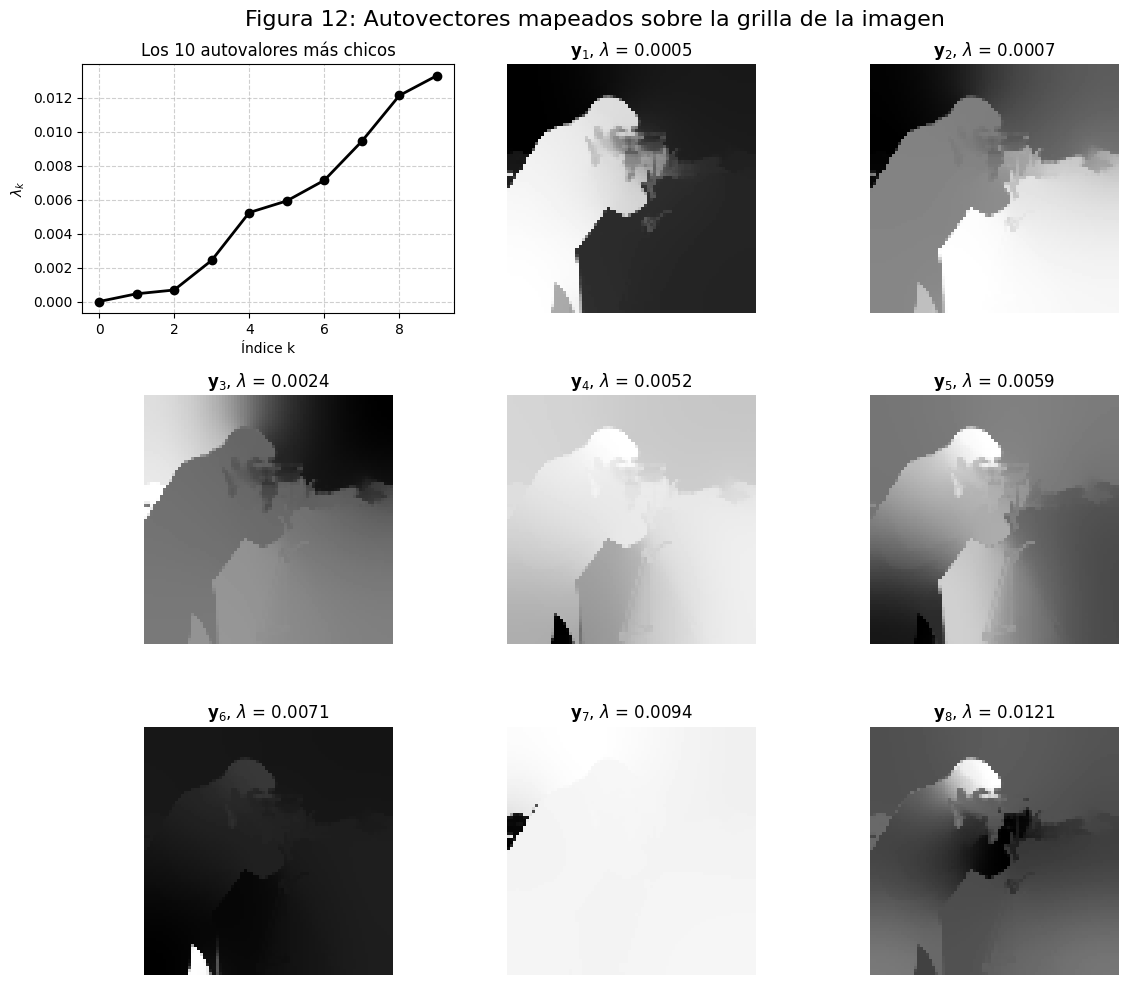

In [ ]:
ANCHO = 80
original = data.camera()
alto = int(round(original.shape[0] * (ANCHO / original.shape[1])))
F = cv2.resize(original, (ANCHO, alto), interpolation=cv2.INTER_AREA).astype(np.float64) / 255.0

H, W_img_cols = F.shape
n_nodos = H * W_img_cols

print(f'Imagen: {H} x {W_img_cols} = {n_nodos:,} píxeles (nodos)')

RADIO, SIGMA_I, SIGMA_D = 5, 0.1, 4.0
t0 = time.time()
W_img = calcular_pesos_en_grafo(F, RADIO, SIGMA_I, SIGMA_D)
tiempo_grafo = time.time() - t0

megabytes_densa = (n_nodos * n_nodos * 8) / 1e6
porcentaje_ocupacion = 100 * W_img.nnz / (n_nodos ** 2)

print(f'Grafo construido en {tiempo_grafo:.1f} s')
print(f'-> Matriz Densa ocuparía: {megabytes_densa:,.0f} MB')
print(f'-> Matriz Dispersa guarda: {W_img.nnz:,} valores ({porcentaje_ocupacion:.2f}% de ocupación)')

#Calculamops autovectores
t0 = time.time()
lam_i, Y_i = autovectores_dispersos(W_img, k=10)
print(f'10 Autovectores calculados en {time.time() - t0:.1f} s')

#Visualizacion
fig, axs = plt.subplots(3, 3, figsize=(12, 10))
axs[0, 0].plot(range(10), lam_i, 'ko-', lw=2)
axs[0, 0].set_xlabel('Índice k'); axs[0, 0].set_ylabel(r'$\lambda_k$')
axs[0, 0].set_title('Los 10 autovalores más chicos')
axs[0, 0].grid(True, linestyle='--', alpha=0.6)

for ax, k in zip(axs.ravel()[1:], range(1, 9)):
    #Reconvertimos el vector unidimensional 1D a la forma 2D de la imagen
    imagen_autovector = Y_i[:, k].reshape(H, W_img_cols)
    ax.imshow(imagen_autovector, cmap='gray')
    ax.axis('off')
    ax.set_title(f'$\\mathbf{{y}}_{{{k}}}$, $\\lambda$ = {lam_i[k]:.4f}')

fig.suptitle('Figura 12: Autovectores mapeados sobre la grilla de la imagen', fontsize=16)
plt.tight_layout()
plt.show()

Observá los autovectores de la figura anterior. $\mathbf{y}_1$ (arriba al centro) marca claramente un contraste brillante vs oscuro.

Evaluemos los histogramas y busquemos el punto de corte (umbral) que minimiza el **Ncut**. Luego, vamos a subdividir la imagen utilizando los siguientes autovectores ($\mathbf{y}_2$ a $\mathbf{y}_5$).

O sea, es un algoritmo recursivo digamos

Corte ciego (Umbral 0): Ncut = 0.0033
Corte óptimo (Umbral 0.0004): Ncut = 0.0028


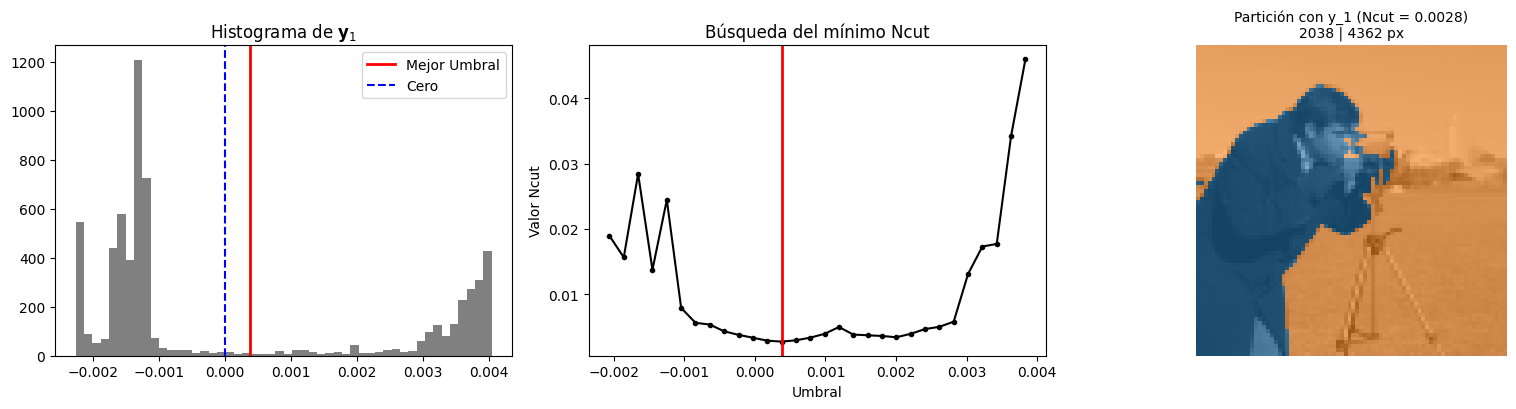

In [ ]:
def mostrar_segmentos(ax, img_base, partes, titulo):
    """Pinta cada segmento (lista de índices) de un color semitransparente sobre la imagen."""
    H, W = img_base.shape
    colores = plt.cm.tab10(np.arange(len(partes)) % 10)[:, :3]

    vis = np.dstack([img_base] * 3).reshape(-1, 3).copy()

    for parte, col in zip(partes, colores):
        vis[parte] = 0.45 * vis[parte] + 0.55 * col

    ax.imshow(vis.reshape(H, W, 3))
    ax.axis('off')
    ax.set_title(titulo + '\n' + ' | '.join(str(len(p)) for p in partes) + ' px', fontsize=10)


#Evaluamos 1er autovector
y1 = Y_i[:, 1]
u1, nc1, umbrales1, valores1 = mejor_umbral(W_img, y1)
A_img = y1 > u1

print(f'Corte ciego (Umbral 0): Ncut = {ncut(W_img, y1 > 0):.4f}')
print(f'Corte óptimo (Umbral {u1:.4f}): Ncut = {nc1:.4f}')

#Graficos
fig, axs = plt.subplots(1, 3, figsize=(16, 4.2))

#Histograma
axs[0].hist(y1, bins=50, color='gray')
axs[0].axvline(u1, color='red', lw=2, label='Mejor Umbral')
axs[0].axvline(0, color='blue', ls='--', label='Cero')
axs[0].legend()
axs[0].set_title(r'Histograma de $\mathbf{y}_1$')

#Curva de Ncut
axs[1].plot(umbrales1, valores1, 'k.-')
axs[1].axvline(u1, color='red', lw=2)
axs[1].set_xlabel('Umbral'); axs[1].set_ylabel('Valor Ncut')
axs[1].set_title('Búsqueda del mínimo Ncut')

#Primer corte aplicado a la imagen
mostrar_segmentos(axs[2], F, [np.nonzero(A_img)[0], np.nonzero(~A_img)[0]], f'Partición con y_1 (Ncut = {nc1:.4f})')
plt.tight_layout()
plt.show()

Si evaluamos subdivisiones


Realizando subdivisiones adicionales...
Evaluando Grupo A (2038 píxeles):
Evaluando Grupo B (4362 píxeles):


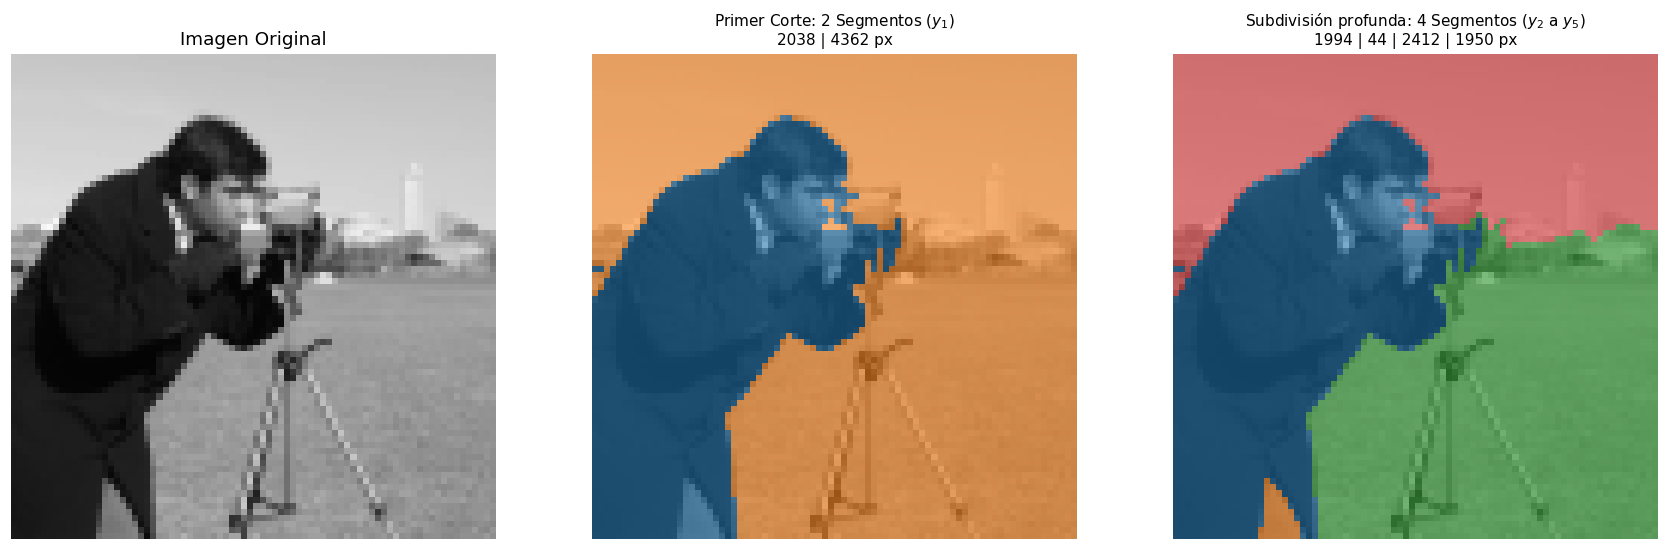

In [ ]:
umbral_optimo_func = lambda W, y: mejor_umbral(W, y)[0]
partes_img = []

print("\nRealizando subdivisiones adicionales...")
for nombre, grupo in [('A', A_img), ('B', ~A_img)]:
    print(f'Evaluando Grupo {nombre} ({grupo.sum()} píxeles):')
    partes_img += subdividir(W_img, Y_i, grupo, [2, 3, 4, 5], umbral_optimo_func)[:2]

fig, axs = plt.subplots(1, 3, figsize=(16, 5))
axs[0].imshow(F, cmap='gray', vmin=0, vmax=1)
axs[0].axis('off')
axs[0].set_title('Imagen Original')

mostrar_segmentos(axs[1], F, [np.nonzero(A_img)[0], np.nonzero(~A_img)[0]], 'Primer Corte: 2 Segmentos ($y_1$)')
mostrar_segmentos(axs[2], F, partes_img, 'Subdivisión profunda: 4 Segmentos ($y_2$ a $y_5$)')
plt.tight_layout()
plt.show()

## B.6: Ncut Recursivo (Sección 3.3)

Hasta ahora recortamos mediante el corte optimo que minimiza **Ncut** produciendo biparticiones y teniendo que ir autovector por autovector viendo cual es que separa mejor...
Por un lado, no es muy atractivo algoritmicamente esto, y por otro lado los autovectores siempre van a tener errores dados por el numero de condición de la matriz.

El paper de Shi y Malik propone una estrategia *Top-Down* (de arriba hacia abajo): el **Corte Normalizado Recursivo**.

### ¿Cómo funciona?
La idea es tomar el grafo original, partirlo en dos usando el segundo autovector (el de menor Ncut), y luego **tratar a cada una de esas dos mitades como un nuevo problema independiente**.
Se extrae el subgrafo correspondiente a esa mitad, se vuelve a calcular su Laplaciano, se buscan sus nuevos autovectores y se vuelve a partir.

### Los tres frenos de emergencia (Criterios de parada)
Si partimos recursivamente sin parar, terminaríamos con cada píxel aislado en su propio segmento. Para que el algoritmo sepa cuándo un pedazo de imagen ya es un "objeto semántico" definitivo y deje de cortarlo, el paper define estrictos criterios de parada:

1. **Costo del corte (`max_ncut`):** Si el mejor Ncut encontrado es demasiado alto, significa que estamos intentando romper un bloque fuertemente unido (muy uniforme). Si el costo supera un límite, el segmento no se divide.
2. **Tamaño mínimo (`min_tam`):** Evita que el algoritmo aísle píxeles ruidosos o texturas minúsculas. Si al cortar un grupo quedan muy pocos píxeles, la partición se rechaza.
3. **Estabilidad del Autovector:** La página 21 del paper indica que si el autovector toma valores muy continuos (como una rampa suave), no hay una frontera natural clara. Si toma valores discretos (como un escalón con un salto brusco), hay un borde fuerte. Si el autovector es inestable, se descarta y se prueba el siguiente ($y_3$, $y_4$, etc.).

A continuación, implementaremos el algoritmo completo guiándonos por este pseudocódigo:

```
dividir(idx):                                  # idx = índices de los nodos del grupo actual
    si len(idx) < 2 * min_tam: es un segmento final
    Ws = W[idx][:, idx]                        # extraemos el subgrafo del grupo
    lam, Y = autovectores_dispersos(Ws, k_max) # calculamos el espectro local
    
    para k = 1, 2, ..., k_max - 1:             # Y[:, 1] es el autovector 2
        si inestabilidad(Y[:, k]) > umbral_estabilidad: probar el siguiente k
        umbral, valor = mejor_umbral(Ws, Y[:, k])
        A = Y[:, k] > umbral
        
        si valor <= max_ncut y ambos lados tienen al menos min_tam nodos:
            dividir(idx[A])                    # recursión lado A
            dividir(idx[~A])                   # recursión lado B
            terminar                           # salimos para no evaluar más autovectores acá
            
    si no se dividió: es un segmento final
```


In [ ]:
def inestabilidad(y):
    """
    Heurística simplificada de la página 21 del paper.
    Mide qué tan 'continuo' es el autovector. Si es muy continuo, no hay una frontera clara para cortar. Retorna un valor entre 0 y 1.
    """
    if y.max() == y.min():
        return 1.0

    # Dividimos en 30 bines y miramos el 50% central.
    # Si hay muchos nodos ahí, no hay una separación clara de 2 grupos (bimodal).
    hist, _ = np.histogram(y, bins=30)
    centro_idx = int(30 * 0.25)
    fraccion_centro = hist[centro_idx:-centro_idx].sum() / len(y)

    return fraccion_centro


def ncut_recursivo(W, max_ncut, umbral_inestabilidad, min_tam, k_max=10):
    """
    Segmentación completa mediante Ncut Recursivo.
    Devuelve: (segmentos, cortes)
      - segmentos: arreglo 1D con el ID de segmento al que pertenece cada nodo.
      - cortes: lista con el registro de los cortes realizados.
    """
    n = W.shape[0]
    segmentos = np.zeros(n, dtype=int)
    cortes = []
    id_segmento = 0

    def dividir(idx, nivel):
        nonlocal id_segmento

        # Freno 1: Tamaño insuficiente para intentar partir
        if len(idx) < 2 * min_tam:
            segmentos[idx] = id_segmento
            id_segmento += 1
            return

        # Extraemos el subgrafo eficientemente
        # En matrices dispersas csr_matrix, esto se hace indexando filas y luego columnas
        Ws = W[idx, :][:, idx]

        # Resolvemos autovectores del subgrafo
        try:
            # Pedimos min(k_max, tamaño-1) porque eigsh no puede buscar más autovectores que dimensiones
            lam, Y = autovectores_dispersos(Ws, min(k_max, len(idx) - 1))
        except Exception as e:
            print(f"  [Nivel {nivel}] Falla en autovectores: {e}. Se declara segmento final.")
            segmentos[idx] = id_segmento
            id_segmento += 1
            return

        # 1. Iterá k desde 1 hasta Y.shape[1] - 1 (para omitir el autovector trivial 0)
        # 2. Evaluá la inestabilidad(Y[:, k]). Si supera el umbral_inestabilidad, probá el siguiente k.
        # 3. Obtené el mejor umbral y su valor Ncut con la función mejor_umbral(Ws, Y[:, k])
        # 4.  Calculá la máscara A = (Y[:, k] > umbral)
        # 5. Si el valor Ncut <= max_ncut, Y ambos lados (A y ~A) tienen al menos min_tam nodos:
        #         - Guardá el corte en la lista `cortes` (ej: {'nivel': nivel, 'ncut': valor})
        #         - Llamá recursivamente a dividir(idx[A], nivel + 1)
        #         - Llamá recursivamente a dividir(idx[~A], nivel + 1)
        #         - Hacé un `return` para no evaluar más autovectores en este subgrafo.

        # Si ningún autovector sirvió para dividir, es un segmento final
        segmentos[idx] = id_segmento
        id_segmento += 1

    # Iniciamos la recursión con todos los nodos (0 a n-1) en el nivel 0
    # Descomentar cuando el TODO esté completo:
    # dividir(np.arange(n), 0)

    return segmentos, cortes

Recursión perfecta. Realizó 3 cortes válidos y formó 4 segmentos finales.


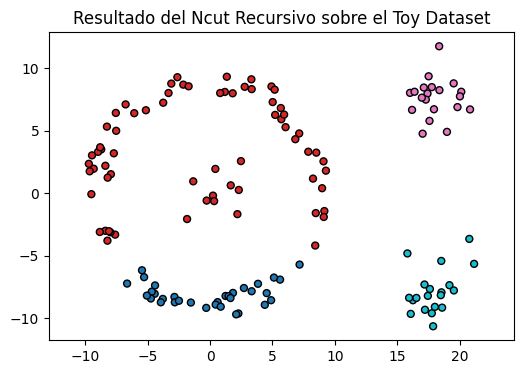

In [ ]:
try:
    MAX_NCUT = 0.10
    UMBRAL_INESTABLE = 0.4
    MIN_TAM = 10


    segs_alumno, cortes_alumno = ncut_recursivo(Wp, MAX_NCUT, UMBRAL_INESTABLE, MIN_TAM)

    n_segmentos = len(np.unique(segs_alumno))
    n_cortes = len(cortes_alumno)

    assert n_segmentos == 4, f"Se esperaban 4 segmentos (anillo, centro y dos islas), pero encontró {n_segmentos}."
    assert n_cortes == 3, f"Para formar 4 segmentos debió hacer exactamente 3 cortes recursivos, pero hizo {n_cortes}."

    print(f"Recursión perfecta. Realizó {n_cortes} cortes válidos y formó {n_segmentos} segmentos finales.")

    # Dibujamos el resultado sobre los puntos
    plt.figure(figsize=(6, 4))
    plt.scatter(*P.T, c=segs_alumno, cmap='tab10', s=25, edgecolor='k')
    plt.title("Resultado del Ncut Recursivo sobre el Toy Dataset")
    plt.axis('equal'); plt.show()

except Exception as e:
    print(f"Error en la lógica recursiva: {e}")

In [ ]:
def cargar_y_preparar_imagen(ancho_max=80):
    """
    Permite subir una imagen y la reduce a la resolución deseada. Devuelve la imagen en RGB para graficar, y normalizado.
    """
    print("Elegí una imagen para segmentar automáticamente:")
    subido = files.upload()

    if not subido:
        print("No se subió imagen. Usando 'Cameraman' por defecto.")
        from skimage import data
        img_rgb = cv2.cvtColor(data.camera(), cv2.COLOR_GRAY2RGB)
    else:
        nombre_archivo = next(iter(subido))
        img_pil = Image.open(io.BytesIO(subido[nombre_archivo])).convert('RGB')
        img_rgb = np.array(img_pil)

    alto = int(round(img_rgb.shape[0] * ancho_max / img_rgb.shape[1]))
    F_rgb = cv2.resize(img_rgb, (ancho_max, alto), interpolation=cv2.INTER_AREA)
    F_norm = F_rgb.astype(np.float64) / 255.0

    return F_rgb, F_norm

#PARAMETROS A CAMBIAR
ANCHO_MAX = 200
RADIO = 10
SIGMA_I = 0.15
SIGMA_D = 4.0

F_rgb, F_norm = cargar_y_preparar_imagen(ancho_max=ANCHO_MAX)
H, W_cols, _ = F_norm.shape
print(f"\nProcesando imagen de {H}x{W_cols} ({H*W_cols} nodos)...")

t0 = time.time()
W_grafo = calcular_pesos_en_grafo(F_norm, RADIO, SIGMA_I, SIGMA_D)
print(f"Grafo de conectividad construido en {time.time()-t0:.1f} segundos.")
print("El grafo está en memoria. Ahora podés probar la segmentación abajo.")

Elegí una imagen para segmentar automáticamente:


Saving images (4).jpg to images (4) (7).jpg

Procesando imagen de 112x200 (22400 nodos)...
Grafo de conectividad construido en 124.2 segundos.
El grafo está en memoria. Ahora podés probar la segmentación abajo.


In [ ]:
def segmentar_y_visualizar(W, img_rgb, max_ncut=0.04, min_tam=400, umbral_estab=0.40, k_max=2):
    """
    Ejecuta el Ncut Recursivo sobre un grafo precalculado y visualiza los resultados.
    """
    H, W_cols, _ = img_rgb.shape

    print(f"Iniciando Ncut Recursivo | Max Ncut: {max_ncut} | Min Tamaño: {min_tam} | K Max: {k_max}")
    t1 = time.time()

    #Llamada al algoritmo recursivo
    segmentos_1d, arbol_cortes = ncut_recursivo(
        W=W,
        max_ncut=max_ncut,
        umbral_inestabilidad=umbral_estab,
        min_tam=min_tam,
        k_max=k_max
    )

    tiempo_total = time.time() - t1
    n_zonas = len(np.unique(segmentos_1d))
    print(f"Terminado en {tiempo_total:.1f} s. Se hicieron {len(arbol_cortes)} cortes formando {n_zonas} segmentos")

    segmentos_2d = segmentos_1d.reshape(H, W_cols)

    #Visualizacion
    fig, axs = plt.subplots(1, 3, figsize=(16, 5))

    #Imagen Original
    axs[0].imshow(img_rgb)
    axs[0].set_title("1. Imagen Original")
    axs[0].axis('off')

    #Mapa de Segmentos (Colores aleatorios)
    axs[1].imshow(segmentos_2d, cmap='tab20')
    axs[1].set_title(f"2. Mapa de Partición ({n_zonas} segmentos)")
    axs[1].axis('off')

    #Fronteras Semánticas
    segmentos_uint8 = ((segmentos_2d / segmentos_2d.max()) * 255).astype(np.uint8) if segmentos_2d.max() > 0 else segmentos_2d.astype(np.uint8)
    borde_mask = cv2.Canny(segmentos_uint8, 0, 1) > 0

    img_bordeada = img_rgb.copy()
    img_bordeada[borde_mask] = [255, 0, 0]

    axs[2].imshow(img_bordeada)
    axs[2].set_title("3. Fronteras Semánticas Detectadas")
    axs[2].axis('off')

    plt.tight_layout()
    plt.show()

Iniciando Ncut Recursivo | Max Ncut: 0.05 | Min Tamaño: 100 | K Max: 10
Terminado en 24.3 s. Se hicieron 6 cortes formando 7 segmentos


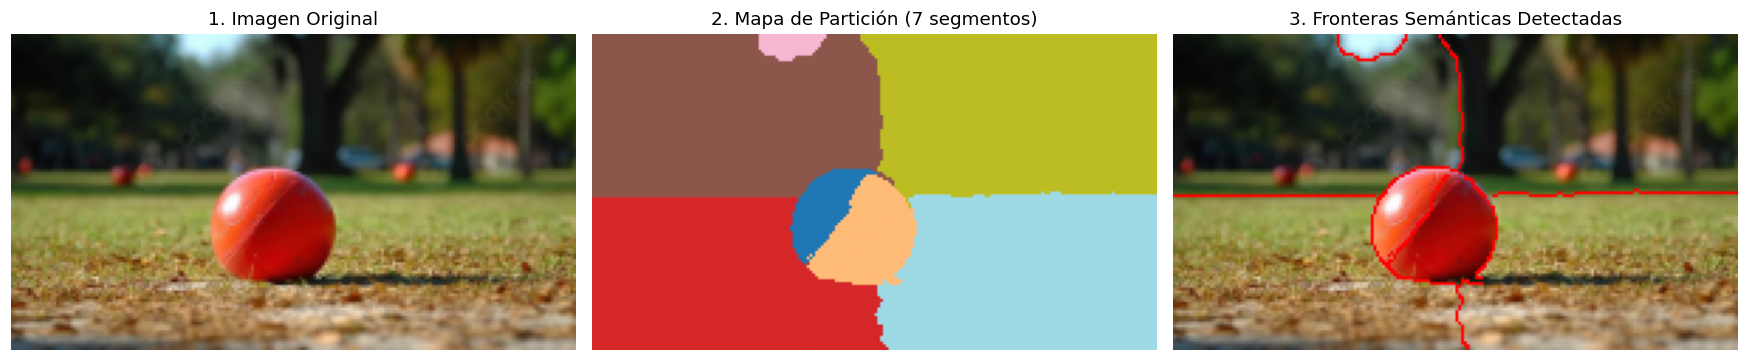

In [ ]:
segmentar_y_visualizar(
    W=W_grafo,
    img_rgb=F_rgb,
    max_ncut=0.05,
    min_tam=100,
    umbral_estab=0.30,
    k_max=10
)

Parametros:

- ANCHO_MAX (Resolución de la imagen):
Un ancho de 80 genera unos 6,400 nodos. Si lo subís a 200, vas a tener 40,000 nodos y la matriz $W$ va a tardar minutos en calcularse y podría saturar la RAM del Colab. Mantenelo bajo para iterar rápido.

- RADIO (Tamaño del vecindario):
Define cuántos vecinos mira cada píxel. Si es muy chico (ej. 2), el algoritmo se vuelve sensible al ruido local. Si lo subís a 10, los bordes serán más suaves pero la matriz $W$ tendrá muchísimas más aristas y el cálculo de autovectores será lentísimo.

- SIGMA_I (Sensibilidad al color): Mide qué tanto toleramos que dos colores sean distintos. Si ponés un SIGMA_I muy chico (0.01), el grafo se desconecta por cualquier sombra. Si lo ponés muy alto (0.5), colores distintos se van a fusionar en el mismo segmento.

- SIGMA_D (Decaimiento por distancia): Penaliza conexiones largas. Suele ir de la mano con el RADIO

- max_ncut Es el costo de corte tolerado. Si la imagen se parte en muchísimos pedacitos inútiles (sobre-segmentación), hay que bajar el max_ncut (ej. 0.02) para poner al algoritmo más "exigente". Si la imagen queda como un solo bloque grande, hay que subirlo (ej. 0.06).

- min_tam (Tamaño mínimo de objeto): Previene que píxeles aislados o reflejos de luz terminen siendo segmentos propios.

- umbral_estab (Filtro de autovectores inestables): Mide el amontonamiento en el medio del histograma. Si lo bajás (ej. 0.20), sos muy estricto y el algoritmo rechazará casi todos los autovectores y dejará de cortar. Si lo subís (ej. 0.80), el algoritmo cortará guiándose por autovectores confusos y las fronteras serán un zigzag sin sentido.

- k_max (Autovectores a explorar por rama):
Si el 2do autovector no sirve (inestable), prueba el 3ro, el 4to... Probar hasta el 5to o 6to suele ser suficiente para encontrar una frontera latente en ese subgrafo.